<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-052-quantum-circuit-compilation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 052 <br>
<hr/>

# Lab 052 — Quantum state compilation with deep Q-learning and policy gradient

A quantum computer prepares a quantum state by applying a sequence of elementary operations, the gates, to a simple initial state. A device offers only a small fixed set of gates, and every gate adds a small error. Compiling a target state therefore means finding a short sequence of gates from this set that turns the initial state into the target, or into a state as close to it as possible. The number of candidate sequences grows exponentially with their length, and already for a few qubits an exhaustive search becomes impossible.

We first introduce the objects of the problem for readers who have met quantum mechanics only once. A qubit state is a complex vector with two entries, a gate is a unitary matrix acting on it, and a circuit is a product of such matrices. We compute one small example explicitly, the preparation of an entangled Bell state of two qubits, and define the fidelity that measures how close a prepared state is to the target.

The targets form four families on chains of $N=2$, $3$, $4$ and $6$ qubits. The Greenberger–Horne–Zeilinger (GHZ) state has a known shortest circuit. The W state has no exact short circuit with our gate set. The ground state of the transverse-field Ising chain belongs to an integrable model that maps to free fermions, and the ground state of the same chain with an additional longitudinal field belongs to a non-integrable model. For every target we compute the entanglement entropy between the two halves of the chain, and for two and three qubits an exhaustive search gives the exact best circuit.

The smallest compilation problem is a single qubit with four 90° pulses as its discrete gate set, brought from $|0\rangle$ to the target $|1\rangle$ with a reward of 1 in $|1\rangle$ and 0 elsewhere. This notebook treats the same kind of Markov decision process with more qubits and more gates, and it replaces the reward of 0 or 1 by the fidelity, which varies continuously between 0 and 1. The gates act without failures.

We then formulate compilation as a reinforcement-learning problem. The agent sees the current state, chooses one gate per step and is rewarded for every gain in fidelity, with a small cost per gate. A neural network approximates the action-value function, and we train it with deep Q-learning (DQN) [V. Mnih *et al.*, Nature **518**, 529 (2015), [doi:10.1038/nature14236](https://doi.org/10.1038/nature14236)] and with double deep Q-learning (DDQN) [H. van Hasselt, A. Guez, D. Silver, Proc. AAAI Conf. Artif. Intell. **30** (2016), [doi:10.1609/aaai.v30i1.10295](https://doi.org/10.1609/aaai.v30i1.10295)]. Both are our reimplementations in JAX, applied to exact state vectors, and they are compared on the same targets and seeds, against the exhaustive search where it is available, and we relate the difficulty of a target to its entanglement. We then estimate the fidelity in the reward from a finite number of measurement shots, as on a real device, and measure how this noise makes DQN overestimate the value of the initial state and how DDQN corrects it. Finally we train a policy-gradient agent, REINFORCE with a baseline, which learns the probabilities of the gates directly, and compare it with DQN and DDQN on the GHZ and W states under the same reward, now with a higher cost for every CNOT, over several seeds and chain lengths. Deep reinforcement learning has also been applied to the compilation of single-qubit unitaries into long sequences of discrete gates, for example by Y.-H. Zhang *et al.*, Phys. Rev. Lett. **125**, 170501 (2020), [doi:10.1103/PhysRevLett.125.170501](https://doi.org/10.1103/PhysRevLett.125.170501), and by L. Moro *et al.*, Commun. Phys. **4**, 178 (2021), [doi:10.1038/s42005-021-00684-3](https://doi.org/10.1038/s42005-021-00684-3).

The code is written in JAX. The quantum states are simulated without building any $2^N\times2^N$ matrix, with the primitives of the SmoQ.jax engine, and the Q-network and its training loop are compiled with `jax.jit`, run for several targets and seeds at once with `jax.vmap` and spread over the CPU cores with `jax.pmap`.

## Student route and recorded benchmark conventions
Begin with [Lab 058](lab-058-finite-budget-ghz.ipynb) for the short finite-budget calculation. In this full study, the classroom reading route runs through target states, the gate set, the compilation environment, DQN and its target, then the trained-circuit figures. Stop there before the extended reward, shot-noise and policy-gradient studies. Running all cells performs the full benchmark.

The saved results below belong to the original implementation. Its DQN input omits remaining budget, and its target bootstraps at budget cutoffs. This means that when an episode stops because the gate limit $n_{\max}$ is reached, the update target still adds $\gamma\max_aQ(s',a)$ for the next state, as if the episode could continue. Only success makes a transition terminal. Its REINFORCE episodes have a finite horizon. The finite-budget exact search therefore supplies a circuit reference with a different continuation convention from the DQN update. The short classroom study includes budget in the state and makes exhaustion terminal. Its results are separate.

Greedy circuits here are selected at their best prefix using exact simulator fidelity. The best prefix is the initial part of the greedy circuit, up to the gate after which the fidelity is highest. This is an evaluation selection procedure. It requires its own observation-based stopping rule on hardware. Reward-to-go training, discounted return, final fidelity and best-prefix fidelity should be distinguished when interpreting the figures.

The finite-shot study adds noise only to reward fidelities. Amplitude observations and the success flag still use the exact simulator state. This isolates reward noise and retains privileged simulator information. Fidelity measurement through the inverse target circuit assumes that circuit is available.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu` and creates one JAX device per CPU core.
> 2. `jax`, `optax` and `matplotlib` are pre-installed in Colab.
> 3. The notebook trains more than three hundred agents. The recorded run took about 17 minutes on a 16-core CPU shared with other jobs, and on the two cores of a free Colab session we expect it to take roughly eight times longer, by the ratio of the core counts. The list `N_LIST` in the targets cell sets the chain lengths. Adding $8$ to it extends the study to eight qubits and makes the training considerably longer. The last cell prints the measured run time.
> 4. Run the cells in order. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"                     # run JAX on the CPU (set before importing jax)
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={os.cpu_count()}"   # one device per core
PRECISION = "single"                                    # complex64 states, float32 networks (read by the engine cell)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import jax, jax.numpy as jnp
import optax

t_start = time.time()
# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "lines.linewidth": 2.0, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}
UJNavy, UJBlue, UJSky, DSOrange, UJGray = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#5A6270"
ALGO_STYLE = {"DQN": dict(color=DSOrange, ls="--"), "DDQN": dict(color=UJBlue, ls="-")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True); os.makedirs("data", exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)
NUMBERS = {}
def thin(n):
    # integers of five or more digits get a thin space between groups of three digits in the LaTeX macros
    return f"{n:,}".replace(",", "\\,") if abs(n) >= 10_000 else str(n)
np.set_printoptions(precision=3, suppress=True)
print("JAX", jax.__version__, "  devices:", len(jax.devices()))

JAX 0.11.0   devices: 16


### Quantum engine

The next cell contains the quantum primitives of the SmoQ.jax engine, copied unchanged from <https://github.com/MarcinPlodzien/SmoQ.jax>. A state of $N$ qubits is a tensor `psi[s_0, ..., s_{N-1}]` of shape $(2,\dots,2)$ with one axis per qubit, and qubit 0 is the most significant bit of the flattened index. A gate acts on its qubits through one `einsum` over their axes, at a cost proportional to $2^N$. Hamiltonians are lists of local terms, and the ground state is found by the Lanczos method, which needs only the product of the Hamiltonian with a state.

In [2]:
# ===== SmoQ.jax engine primitives (copied from https://github.com/MarcinPlodzien/SmoQ.jax) =====
import os, string
import numpy as np
import jax
import jax.numpy as jnp

PRECISION = globals().get("PRECISION", os.environ.get("QE_PRECISION", "double"))
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # 52 einsum labels; a call needs (axes + new labels) <= 52: apply_gate on a state
                                 # N + k <= 52 (N <= 51 for k = 1), apply_gate_dm 2N + k <= 52 (N <= 25 for k = 1, 2),
                                 # apply_kraus_dm 2N + 2k + 1 <= 52 (N <= 24 for k = 1, N <= 23 for k = 2)

I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
H = jnp.array([[1, 1], [1, -1]], dtype=CDTYPE) / jnp.sqrt(2.0)      # Hadamard: Z-basis <-> X-basis
S = jnp.array([[1, 0], [0, 1j]], dtype=CDTYPE)                      # phase gate, S^2 = Z
T = jnp.array([[1, 0], [0, jnp.exp(1j * jnp.pi / 4)]], dtype=CDTYPE)  # pi/8 gate, T^2 = S (non-Clifford!)
CNOT = jnp.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=CDTYPE)
XX = jnp.kron(X, X)
YY = jnp.kron(Y, Y)
ZZ = jnp.kron(Z, Z)

def apply_gate(psi, U, qubits):
    """Apply a k-qubit operator U to the axes `qubits` of the tensor `psi`.

    MATH
    ----
    One qubit (k=1), target q:
        psi'[s_0,..,a,..,s_{N-1}] = sum_b  U[a,b] psi[s_0,..,b,..,s_{N-1}]
    Two qubits (k=2), targets (q1,q2); the 4x4 matrix is reshaped to U[a1,a2,b1,b2]:
        psi'[.., a1, .., a2, ..] = sum_{b1,b2} U[a1,a2,b1,b2] psi[.., b1, .., b2, ..]
    This IS the action of (1 x .. x U x .. x 1) -- written without ever building it.

    EINSUM TRANSLATION  (generated automatically below)
    ------------------
        N=3, q=1        :  "db,abc->adc"          d = new (output) index of qubit 1
        N=4, q=(1,3)    :  "efbd,abcd->aecf"      e,f = new indices of qubits 1 and 3
    Recipe: label the axes of psi with letters a,b,c,...; give every target qubit a NEW
    letter (the next unused ones); U carries (new letters)+(old letters of the targets); the
    output is psi's labels with the target letters replaced by the new ones.

    IMPLEMENTATION NOTES
    --------------------
    * reshape of U:  (2^k,2^k) -> (2,)*2k.  Row index = (a1..ak), column = (b1..bk), and
      the FIRST qubit in `qubits` is the most significant bit of the small matrix, i.e. it
      corresponds to the LEFT factor of kron(A,B).
    * `qubits` may be any distinct axes in any order: non-neighbouring gates cost the same.
    * U need not be unitary: projectors, Kraus operators and Hamiltonian terms reuse this.
    * psi may be ANY tensor with those axes of size 2: a state (rank N), a density tensor
      (rank 2N: ket axes 0..N-1, bra axes N..2N-1), ...
    COST   O(2^k * 2^N) operations, O(2^N) memory  (dense matrix: O(4^N) both).
    JAX    `qubits` must be static Python ints (they define the einsum string); psi and U are
           traced, so the function can sit inside jit / grad / vmap / scan.
    """
    qubits = tuple(int(q) for q in qubits)
    k, n = len(qubits), psi.ndim
    U = jnp.asarray(U, dtype=psi.dtype).reshape((2,) * (2 * k))     # matrix -> rank-2k tensor
    inp = list(_LETTERS[:n])                                         # labels of psi's axes
    new = _LETTERS[n:n + k]                                          # fresh labels for the outputs
    out = inp.copy()
    for a, q in zip(new, qubits):
        out[q] = a                                                   # target axes get the new labels
    sub = f"{''.join(new)}{''.join(inp[q] for q in qubits)},{''.join(inp)}->{''.join(out)}"
    return jnp.einsum(sub, U, psi)


def zero_state(N):
    """|00...0>: a rank-N tensor of zeros with a single 1 at index (0,0,...,0).
    JAX arrays are immutable: `.at[idx].set(v)` returns an updated COPY (functional style)."""
    return jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)


def ghz_state(N):
    """GHZ state (|0...0> + |1...1>)/sqrt(2): two non-zero entries of the rank-N tensor."""
    psi = jnp.zeros((2,) * N, dtype=CDTYPE)
    return psi.at[(0,) * N].set(1 / jnp.sqrt(2.0)).at[(1,) * N].set(1 / jnp.sqrt(2.0))


def dicke_state(N, k):
    """Symmetric Dicke state |D_N^k>: equal superposition of all basis states with exactly k ones.
    Implementation: mask of the flat indices with popcount == k, normalised by sqrt(binom(N,k))."""
    idx = np.arange(2 ** N)
    pop = np.array([bin(i).count("1") for i in idx])
    v = (pop == k).astype(np.complex128)
    return jnp.asarray(v / np.linalg.norm(v), dtype=CDTYPE).reshape((2,) * N)


def w_state(N):
    """W state = Dicke state with one excitation: (|10..0> + |01..0> + ... + |0..01>)/sqrt(N)."""
    return dicke_state(N, 1)


def haar_state(key, N):
    """Haar-random pure state: a complex Gaussian vector, normalised.
    (The Gaussian measure is unitarily invariant, so the direction is uniformly distributed.)
    `key` is an explicit JAX PRNG key -- same key, same state: reproducible science."""
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (2,) * N) + 1j * jax.random.normal(k2, (2,) * N)
    return (v / jnp.linalg.norm(v)).astype(CDTYPE)


def schmidt_values(psi, subsystem):
    """Schmidt coefficients of the bipartition A|B with A = `subsystem`.

    MATH   Group the tensor axes into a matrix  M[(a),(b)] = psi[a,b]  of shape (2^|A|, 2^|B|).
           Its SVD  M = U diag(lambda) V^dag  IS the Schmidt decomposition
               |psi> = sum_k lambda_k |u_k>_A |v_k>_B ,     rho_A has eigenvalues lambda_k^2.
    IMPLEMENTATION   transpose (A axes first) -> reshape -> svd.   No density matrix needed.
    """
    A = tuple(int(q) for q in subsystem)
    B = tuple(q for q in range(psi.ndim) if q not in A)
    M = jnp.transpose(psi, A + B).reshape(2 ** len(A), -1)
    return jnp.linalg.svd(M, compute_uv=False)


def entanglement_entropy(psi, subsystem, base=2.0):
    """Entanglement entropy S_A = -sum_k p_k log p_k with p_k = lambda_k^2 (squared Schmidt values).
    Product state: 0.  Bell/GHZ across any cut: 1 bit.  Random state: ~ |A| - 1/(2 ln2) 2^{|A|-|B|} (Page)."""
    p = jnp.clip(schmidt_values(psi, subsystem) ** 2, 1e-16, None)
    return -jnp.sum(p * jnp.log(p)) / jnp.log(base)


def fidelity_pure(psi, phi):
    """F = |<psi|phi>|^2 between two pure states."""
    return jnp.abs(jnp.vdot(psi, phi)) ** 2


def heisenberg_terms(N, Jxx=1.0, Jyy=1.0, Jzz=1.0, hx=0.0, hy=0.0, hz=0.0, periodic=False, bonds=None):
    """Spin-1/2 Hamiltonian in Pauli convention
        H = sum_<ij> (Jxx X_i X_j + Jyy Y_i Y_j + Jzz Z_i Z_j) + sum_i (hx X_i + hy Y_i + hz Z_i)
    returned as a LIST of local terms [(qubits, small_matrix), ...]  -- this list *is* our Hamiltonian.
      Heisenberg: Jxx=Jyy=Jzz     XXZ: Jxx=Jyy!=Jzz     XY: Jzz=0     TFIM: only Jzz and hx.
    `bonds` overrides the default open chain (any graph: ladders, 2D lattices, all-to-all, ...)."""
    if bonds is None:
        bonds = [(i, i + 1) for i in range(N - 1)] + ([(N - 1, 0)] if periodic and N > 2 else [])
    terms = [((i, j), Jxx * XX + Jyy * YY + Jzz * ZZ) for (i, j) in bonds]
    if hx != 0 or hy != 0 or hz != 0:
        terms += [((i,), hx * X + hy * Y + hz * Z) for i in range(N)]
    return terms


def apply_hamiltonian(terms, psi):
    """H|psi> = sum_k h_k|psi>, every term applied with `apply_gate` (h_k is Hermitian, not unitary --
    the einsum does not care).  Cost O(#terms * 2^N).  This matrix-vector product is ALL that Lanczos,
    Chebyshev and Krylov methods need, which is why they scale to N ~ 25-30."""
    out = jnp.zeros_like(psi)
    for qubits, h in terms:
        out = out + apply_gate(psi, h, qubits)
    return out


def dense_hamiltonian(terms, N):
    """Dense 2^N x 2^N matrix for VALIDATION on small N -- built from the matrix-free action:
    column j of H is H|e_j>.   `jax.vmap` applies H to all basis vectors at once."""
    eye = jnp.eye(2 ** N, dtype=CDTYPE).reshape((2 ** N,) + (2,) * N)
    cols = jax.vmap(lambda e: apply_hamiltonian(terms, e).reshape(-1))(eye)
    return cols.T


def lanczos(matvec, v0, m=60, reorth=True):
    """m-step Lanczos iteration: orthonormal basis V of the Krylov space span{v, Hv, H^2 v, ...}
    in which H is TRIDIAGONAL:   T = V^dag H V = tridiag(beta, alpha, beta).

    Recurrence     w = H v_j - alpha_j v_j - beta_{j-1} v_{j-1},   alpha_j = <v_j|H|v_j>,   beta_j = ||w||.
    `reorth=True`  re-orthogonalises against all previous vectors (cures the loss of orthogonality of
                   floating-point Lanczos at the price of O(m^2) inner products).
    Only `matvec` (H|psi>) is needed -> matrix-free.  Returns (alphas, betas, V[m, 2,..,2]).
    """
    v = v0 / jnp.linalg.norm(v0)
    V, alphas, betas = [v], [], []
    w = matvec(v)
    for j in range(m):
        a = jnp.real(jnp.vdot(V[j], w))
        alphas.append(a)
        w = w - a * V[j] - (betas[-1] * V[j - 1] if j > 0 else 0.0)
        if reorth:
            for u in V:
                w = w - jnp.vdot(u, w) * u
        b = jnp.linalg.norm(w)
        if j == m - 1 or float(b) < 1e-12:
            break
        betas.append(b)
        V.append(w / b)
        w = matvec(V[-1])
    return np.array(alphas, dtype=float), np.array(betas, dtype=float), jnp.stack(V)


def lanczos_ground_state(terms, N, m=80, key=None, restarts=3):
    """Ground state (E_0, |psi_0>) from restarted Lanczos: diagonalise the small T, map its lowest
    eigenvector back with V, use it as the next start vector.  Extremal eigenvalues converge first."""
    key = jax.random.PRNGKey(0) if key is None else key
    v = haar_state(key, N)
    mv = jax.jit(lambda p: apply_hamiltonian(terms, p))
    E = None
    for _ in range(restarts):
        a, b, V = lanczos(mv, v, m)
        w, S_ = np.linalg.eigh(np.diag(a) + np.diag(b, 1) + np.diag(b, -1))
        v = jnp.tensordot(jnp.asarray(S_[:, 0], dtype=CDTYPE), V, axes=1)
        v = v / jnp.linalg.norm(v)
        E = w[0]
    return float(E), v

The primitives are checked against dense linear algebra on a random state of four qubits. A two-qubit gate applied with `apply_gate` must agree with the Kronecker-product matrix acting on the flattened vector, every gate must conserve the norm, and the matrix-free Hamiltonian must agree with its dense form.

In [3]:
psi_r = haar_state(jax.random.PRNGKey(1), 4)
dense_cnot_12 = jnp.kron(jnp.kron(I2, CNOT), I2)                 # CNOT with control 1 and target 2, as a 16x16 matrix
err_gate = jnp.abs(apply_gate(psi_r, CNOT, (1, 2)).reshape(-1) - dense_cnot_12 @ psi_r.reshape(-1)).max()
err_h = jnp.abs(apply_gate(psi_r, H, (3,)).reshape(-1) - jnp.kron(jnp.eye(8, dtype=CDTYPE), H) @ psi_r.reshape(-1)).max()
norms = [float(jnp.linalg.norm(apply_gate(psi_r, U, q))) for U, q in [(H, (0,)), (S, (2,)), (T, (1,)), (CNOT, (3, 0))]]
terms_r = heisenberg_terms(4, Jxx=0.0, Jyy=0.0, Jzz=-1.0, hx=-0.7, hz=-0.3)
err_ham = jnp.abs(apply_hamiltonian(terms_r, psi_r).reshape(-1) - dense_hamiltonian(terms_r, 4) @ psi_r.reshape(-1)).max()
print(f"apply_gate against the Kronecker matrix:  CNOT {err_gate:.1e},  H {err_h:.1e}")
print("norm after H, S, T, CNOT:", np.round(norms, 6))
print(f"matrix-free Hamiltonian against the dense matrix: {err_ham:.1e}")

apply_gate against the Kronecker matrix:  CNOT 0.0e+00,  H 0.0e+00
norm after H, S, T, CNOT: [1. 1. 1. 1.]
matrix-free Hamiltonian against the dense matrix: 1.2e-07


All three differences are at the level of the single-precision rounding error, about $10^{-7}$ or below, and the norm stays 1 for every gate. The `einsum` contraction acts as the large Kronecker-product matrix, which the rest of the notebook never builds.

<hr/>
## 1. One qubit

A classical bit is either 0 or 1. A qubit is a quantum two-level system, for example the spin of an electron or two energy levels of an atom. Its state is a normalised complex vector in a two-dimensional space with the basis vectors
$$|0\rangle=\begin{pmatrix}1\\0\end{pmatrix},\qquad |1\rangle=\begin{pmatrix}0\\1\end{pmatrix}.$$
A general state is the superposition
$$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle=\begin{pmatrix}\alpha\\ \beta\end{pmatrix},\qquad |\alpha|^2+|\beta|^2=1 .$$
The complex numbers $\alpha$ and $\beta$ are the amplitudes. A measurement in the basis $\{|0\rangle,|1\rangle\}$ gives the outcome 0 with probability $|\alpha|^2$ and the outcome 1 with probability $|\beta|^2$. Multiplying the whole vector by a phase factor $e^{i\chi}$ changes no measurement probability, so $|\psi\rangle$ and $e^{i\chi}|\psi\rangle$ describe the same physical state. Without this global phase a qubit state is fixed by two real numbers, the angles $\theta\in[0,\pi]$ and $\varphi\in[0,2\pi)$ in
$$|\psi\rangle=\cos\frac{\theta}{2}\,|0\rangle+e^{i\varphi}\sin\frac{\theta}{2}\,|1\rangle .$$
They are the polar and azimuthal angles of a point on the unit sphere, the Bloch sphere. The north pole is $|0\rangle$ and the south pole is $|1\rangle$. The equator holds the equal superpositions, among them
$$|\pm\rangle=\frac{|0\rangle\pm|1\rangle}{\sqrt2}\quad(\pm x\text{ axis}),\qquad |\pm i\rangle=\frac{|0\rangle\pm i|1\rangle}{\sqrt2}\quad(\pm y\text{ axis}).$$
Opposite points on the sphere are orthogonal states.

### Gates

A gate changes the state of a qubit. Quantum mechanics requires that it maps normalised vectors to normalised vectors, so a gate is a unitary $2\times2$ matrix $\hat U$, with $\hat U^\dagger \hat U=\mathbb 1$, and the new state is the matrix product $\hat U|\psi\rangle$. On the Bloch sphere every single-qubit gate is a rotation. We use five standard gates.

| gate | matrix | action on the Bloch sphere |
|---|---|---|
| $\hat X$ (NOT) | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | rotation by $\pi$ about the $x$ axis, $\lvert0\rangle\leftrightarrow\lvert1\rangle$ |
| $\hat H$ (Hadamard) | $\frac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | rotation by $\pi$ about the axis $(x+z)/\sqrt2$, $\lvert0\rangle\leftrightarrow\lvert+\rangle$ |
| $\hat Z$ | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | rotation by $\pi$ about the $z$ axis |
| $\hat S$ (phase) | $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ | rotation by $\pi/2$ about the $z$ axis, $\lvert+\rangle\to\lvert+i\rangle$ |
| $\hat T$ | $\begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}$ | rotation by $\pi/4$ about the $z$ axis |

The gates $\hat Z$, $\hat S$ and $\hat T$ multiply the amplitude of $|1\rangle$ by a phase and leave the probabilities of 0 and 1 unchanged. They change the relative phase $\varphi$, which is a rotation about the $z$ axis. The relations $\hat S=\hat T^2$ and $\hat Z=\hat S^2$ follow from the matrices. The next cell checks unitarity and follows $|0\rangle$ through $\hat H$ and then $\hat S$, with the Bloch vector $(\langle \hat X\rangle,\langle \hat Y\rangle,\langle \hat Z\rangle)$ of each state.

In [4]:
for name, U in [("X", X), ("H", H), ("Z", Z), ("S", S), ("T", T)]:
    print(f"{name}: unitary = {bool(jnp.allclose(U.conj().T @ U, I2, atol=1e-6))}")
print("S = T^2:", bool(jnp.allclose(S, T @ T, atol=1e-6)), "   Z = S^2:", bool(jnp.allclose(Z, S @ S, atol=1e-6)))

def bloch_vector(psi):
    # (<X>, <Y>, <Z>) of a single-qubit state
    return np.array([float(jnp.real(jnp.vdot(psi, apply_gate(psi, P, (0,))))) for P in (X, Y, Z)])

ket0 = zero_state(1)
plus = apply_gate(ket0, H, (0,))
plus_i = apply_gate(plus, S, (0,))
for name, v in [("|0>", ket0), ("H|0>", plus), ("S H|0>", plus_i)]:
    print(f"{name:7s} amplitudes {np.asarray(v).round(3)}   Bloch vector {bloch_vector(v).round(3)}")

X: unitary = True
H: unitary = True
Z: unitary = True
S: unitary = True
T: unitary = True
S = T^2: True    Z = S^2: True


|0>     amplitudes [1.+0.j 0.+0.j]   Bloch vector [0. 0. 1.]
H|0>    amplitudes [0.707+0.j 0.707+0.j]   Bloch vector [ 1.  0. -0.]
S H|0>  amplitudes [0.707+0.j    0.   +0.707j]   Bloch vector [ 0.  1. -0.]


The printed Bloch vectors are $(0,0,1)$ for $|0\rangle$, $(1,0,0)$ for $\hat H|0\rangle=|+\rangle$ and $(0,1,0)$ for $SH|0\rangle=|+i\rangle$, the north pole and the points on the $x$ and $y$ axes of the sphere.

The drawing shows the six states on the axes of the Bloch sphere and the rotations produced by three gates. The Hadamard gate takes $|0\rangle$ at the north pole to $|+\rangle$ on the equator, the phase gate $\hat S$ turns $|+\rangle$ by a quarter turn about the $z$ axis to $|+i\rangle$, and $\hat X$ takes $|0\rangle$ to $|1\rangle$. The coloured curves are the paths of a rotation about the axis of each gate, from the initial to the final state.

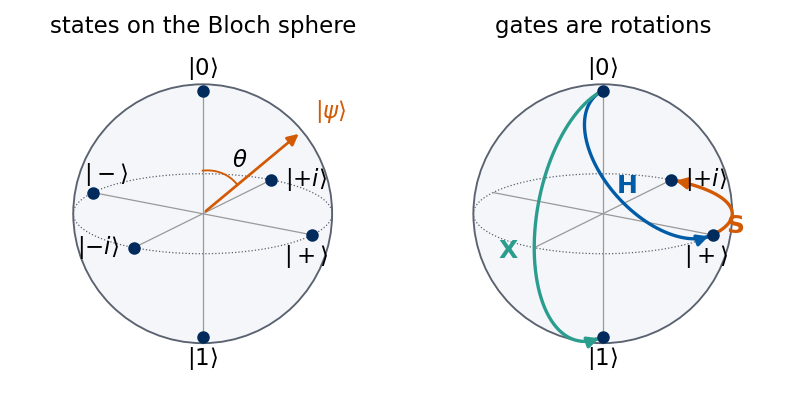

In [5]:
def rodrigues(v, axis, ang):
    # rotate the vector v by the angle ang about the unit vector axis
    k = axis / np.linalg.norm(axis)
    return v * np.cos(ang) + np.cross(k, v) * np.sin(ang) + k * (k @ v) * (1 - np.cos(ang))

EL, AZ = np.deg2rad(18), np.deg2rad(-58)              # viewing angles of the drawing
def proj(p):
    x, y, z = p
    return np.array([-np.sin(AZ) * x + np.cos(AZ) * y,
                     -np.sin(EL) * np.cos(AZ) * x - np.sin(EL) * np.sin(AZ) * y + np.cos(EL) * z])

def draw_sphere(ax):
    t = np.linspace(0, 2 * np.pi, 200)
    ax.add_patch(Circle((0, 0), 1, fc="#F4F6F9", ec=UJGray, lw=0.9))
    ax.plot(*np.array([proj((np.cos(s), np.sin(s), 0)) for s in t]).T, color=UJGray, lw=0.6, ls=":")
    for e in np.eye(3):
        ax.plot(*np.c_[proj(-e), proj(e)], color="0.6", lw=0.6)
    ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal"); ax.axis("off")

def dot(ax, p, label, off):
    q = proj(p)
    ax.plot(*q, "o", ms=5, color=UJNavy, zorder=5)
    ax.text(*(q + off), label, ha="center", va="center", fontsize=11)

six = {r"$|0\rangle$": ((0, 0, 1), (0, 0.17)), r"$|1\rangle$": ((0, 0, -1), (0, -0.17)),
       r"$|+\rangle$": ((1, 0, 0), (-0.05, -0.17)), r"$|-\rangle$": ((-1, 0, 0), (0.1, 0.14)),
       r"$|{+i}\rangle$": ((0, 1, 0), (0.27, 0.0)), r"$|{-i}\rangle$": ((0, -1, 0), (-0.28, 0.0))}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.7))
    ax = axs[0]; draw_sphere(ax)
    for lab, (p, off) in six.items():
        dot(ax, np.array(p, float), lab, np.array(off))
    th, ph = 0.95, 0.9                                 # an example state with angles theta, phi
    p = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
    ax.annotate("", xy=proj(p), xytext=proj((0, 0, 0)), arrowprops=dict(arrowstyle="-|>", color=DSOrange, lw=1.3))
    ax.text(*(proj(p) + [0.1, 0.1]), r"$|\psi\rangle$", color=DSOrange, fontsize=11)
    arc = np.array([proj(rodrigues(np.array([0, 0, 0.35]), np.array([-np.sin(ph), np.cos(ph), 0]), s))
                    for s in np.linspace(0, th, 30)])
    ax.plot(*arc.T, color=DSOrange, lw=0.9); ax.text(*(arc[15] + [0.07, 0.05]), r"$\theta$", fontsize=11)
    ax.set_title("states on the Bloch sphere")
    ax = axs[1]; draw_sphere(ax)
    paths = [("H", np.array([1, 0, 1]) / np.sqrt(2), np.pi, np.array([0, 0, 1.0]), UJBlue, [0.13, 0.02]),
             ("S", np.array([0, 0, 1.0]), np.pi / 2, np.array([1.0, 0, 0]), DSOrange, [0.05, -0.17]),
             ("X", np.array([1.0, 0, 0]), np.pi, np.array([0, 0, 1.0]), "#2A9D8F", [-0.2, 0.0])]
    for name, axis, ang, v0, col, off in paths:
        pts = np.array([proj(rodrigues(v0, axis, s)) for s in np.linspace(0, ang, 60)])
        ax.plot(*pts.T, color=col, lw=1.6)
        ax.annotate("", xy=pts[-1], xytext=pts[-4], arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
        ax.text(*(pts[len(pts) // 2] + off), name, color=col, fontsize=12, ha="center", va="center", fontweight="bold")
    for lab in [r"$|0\rangle$", r"$|1\rangle$", r"$|+\rangle$", r"$|{+i}\rangle$"]:
        p, off = six[lab]; dot(ax, np.array(p, float), lab, np.array(off))
    ax.set_title("gates are rotations")
    fig.tight_layout(); save(fig, "fig_lab052_bloch"); plt.show()

Each gate of the table moves a point of the sphere along a circle about its axis, and a sequence of gates is a sequence of such rotations. Preparing a single-qubit state therefore means finding rotations that carry the north pole to the target point.

<hr/>
## 2. Several qubits and the controlled-NOT gate

The state of $N$ qubits lives in the $2^N$-dimensional space spanned by the basis states $|b_0b_1\dots b_{N-1}\rangle$ with $b_q\in\{0,1\}$, where the digit $b_q$ belongs to qubit $q$. For two qubits these are $|00\rangle,|01\rangle,|10\rangle,|11\rangle$, the tensor (Kronecker) products such as $|01\rangle=|0\rangle\otimes|1\rangle$, and a general state has four complex amplitudes,
$$|\psi\rangle=c_{00}|00\rangle+c_{01}|01\rangle+c_{10}|10\rangle+c_{11}|11\rangle,\qquad \sum_{jk}|c_{jk}|^2=1 .$$
A single-qubit gate $\hat U$ on qubit 0 of two qubits is the $4\times4$ matrix $\hat U\otimes\mathbb 1$. The engine never builds this matrix. It stores the amplitudes as a tensor $c[b_0,b_1]$ and contracts $\hat U$ with the axis of qubit 0. The controlled-NOT gate $\widehat{\mathrm{CNOT}}_{0\to1}$ flips qubit 1 when qubit 0 is in $|1\rangle$ and does nothing otherwise,
$$\widehat{\mathrm{CNOT}}_{0\to1}=|0\rangle\langle0|\otimes\mathbb 1+|1\rangle\langle1|\otimes \hat X=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}.$$
Qubit 0 is the control and qubit 1 the target. The gate $\widehat{\mathrm{CNOT}}_{1\to0}$ has the roles exchanged.

A circuit is a sequence of gates, drawn as horizontal wires, one per qubit, with the gates placed on them from left to right in the order in which they act. The circuit applies the product of the gate matrices to the initial state. The first gate acts first, so it stands rightmost in the product. A circuit with the gates $\hat U_1,\hat U_2,\dots,\hat U_n$ prepares
$$|\psi_n\rangle=\hat U_n\cdots \hat U_2\hat U_1|\psi_0\rangle .$$

### Bell state

We start from $|00\rangle$ and apply first $\hat H$ to qubit 0 and then $\widehat{\mathrm{CNOT}}_{0\to1}$. The Hadamard gate creates a superposition on qubit 0,
$$(\hat H\otimes\mathbb 1)\,|00\rangle=\frac{|0\rangle+|1\rangle}{\sqrt2}\otimes|0\rangle=\frac{|00\rangle+|10\rangle}{\sqrt2}.$$
The CNOT leaves $|00\rangle$ unchanged and maps $|10\rangle$ to $|11\rangle$, so the result is the Bell state
$$|\Phi^+\rangle=\widehat{\mathrm{CNOT}}_{0\to1}(\hat H\otimes\mathbb 1)|00\rangle=\frac{|00\rangle+|11\rangle}{\sqrt2}.$$
This state cannot be written as a product of two single-qubit states. The two qubits are entangled, and measuring both always gives equal results, 00 or 11 with probability $1/2$ each. Single-qubit gates alone never create entanglement, so at least one two-qubit gate is needed to prepare $|\Phi^+\rangle$ from $|00\rangle$. The next cell repeats the calculation with the engine.

In [6]:
psi00 = zero_state(2)
step1 = apply_gate(psi00, H, (0,))
step2 = apply_gate(step1, CNOT, (0, 1))
print("amplitudes c[b0, b1] after H on qubit 0:\n", np.asarray(step1).real.round(3))
print("after CNOT_{0->1}:\n", np.asarray(step2).real.round(3))
print("equal to the GHZ state of two qubits (|00>+|11>)/sqrt2:", bool(jnp.allclose(step2, ghz_state(2), atol=1e-6)))

amplitudes c[b0, b1] after H on qubit 0:
 [[0.707 0.   ]
 [0.707 0.   ]]
after CNOT_{0->1}:
 [[0.707 0.   ]
 [0.    0.707]]
equal to the GHZ state of two qubits (|00>+|11>)/sqrt2: True


The tensor printed after the CNOT has the entries $1/\sqrt2\approx0.707$ at $c[0,0]$ and $c[1,1]$ and zeros elsewhere, which is the Bell state of the calculation above. The Bell state is the GHZ state of two qubits, and the engine function `ghz_state(2)` returns the same tensor.

The circuit drawing of the same example shows the two wires, the Hadamard box on qubit 0 and the CNOT, whose control is the filled dot and whose target is the circle with a cross. Under each stage we write the state of the two qubits.

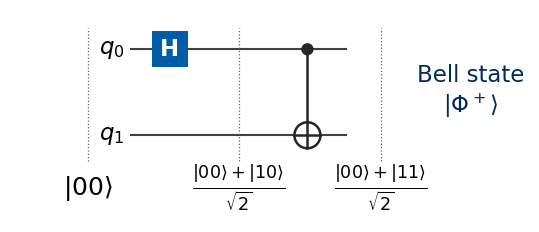

In [7]:
def draw_circuit(ax, gates, N, x0=0.0, dx=1.0, y0=0.0, dy=0.75, pad=0.45, labels=True, box_size=0.42):
    # gates: names 'H0', 'S1', 'T2', 'CX01' (control 0, target 1); qubit 0 on the top wire
    wy = [y0 + (N - 1 - q) * dy for q in range(N)]
    xe = x0 + (max(len(gates), 1) - 1) * dx + pad
    for q in range(N):
        ax.plot([x0 - pad, xe], [wy[q]] * 2, color="0.25", lw=1.0, zorder=1)
        if labels:
            ax.text(x0 - pad - 0.08, wy[q], f"$q_{q}$", ha="right", va="center", fontsize=11)
    box = {"H": UJBlue, "S": "#2A9D8F", "T": DSOrange}
    for k, g in enumerate(gates):
        x = x0 + k * dx
        if g.startswith("CX"):
            c, t = int(g[2]), int(g[3]); r = 0.36 * box_size
            ax.plot([x, x], [wy[c], wy[t]], color="0.15", lw=1.2, zorder=2)
            ax.add_patch(Circle((x, wy[c]), 0.14 * box_size, color="0.15", zorder=3))
            ax.add_patch(Circle((x, wy[t]), r, fc="white", ec="0.15", lw=1.2, zorder=3))
            ax.plot([x - r, x + r], [wy[t]] * 2, color="0.15", lw=1.2, zorder=4)
            ax.plot([x, x], [wy[t] - r, wy[t] + r], color="0.15", lw=1.2, zorder=4)
        else:
            q = int(g[1:])
            ax.add_patch(Rectangle((x - box_size / 2, wy[q] - box_size / 2), box_size, box_size, fc=box[g[0]], ec="none", zorder=3))
            ax.text(x, wy[q], g[0], color="white", ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
    return xe

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 1.75))
    draw_circuit(ax, ["H0", "CX01"], 2, x0=1.5, dx=1.6, dy=1.0)
    for x, s in [(0.55, r"$|00\rangle$"), (2.3, r"$\frac{|00\rangle+|10\rangle}{\sqrt{2}}$"),
                 (3.95, r"$\frac{|00\rangle+|11\rangle}{\sqrt{2}}$")]:
        ax.text(x, -0.62, s, ha="center", va="center", fontsize=12)
        ax.plot([x, x], [-0.3, 1.25], color=UJGray, lw=0.6, ls=":")
    ax.text(5.0, 0.5, "Bell state\n" + r"$|\Phi^+\rangle$", ha="center", va="center", fontsize=11, color=UJNavy)
    ax.set_xlim(-0.3, 5.6); ax.set_ylim(-0.95, 1.4); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab052_bell_circuit"); plt.show()

### Fidelity and the cost of every gate

The fidelity between a prepared state $|\psi\rangle$ and the target $|\psi_{\rm target}\rangle$,
$$F=|\langle\psi_{\rm target}|\psi\rangle|^2\in[0,1],$$
is the probability that a measurement which tests for the target state finds it. It equals 1 only when the two states agree up to a global phase, and it vanishes for orthogonal states. For the initial state $|00\rangle$ and the Bell target $F=1/2$, and after the two gates of the example $F=1$.

On real hardware every gate is imperfect. In the simplest model each gate fails independently with probability $p$, and a circuit of $n$ gates runs without any error with probability $(1-p)^n$, which decreases exponentially with $n$. The cell below evaluates this model for $p=0.01$. A shorter circuit for the same target is therefore a better circuit.

In [8]:
print(f"F(|00>, Bell) = {float(fidelity_pure(ghz_state(2), psi00)):.3f}    F(prepared, Bell) = {float(fidelity_pure(ghz_state(2), step2)):.3f}")
p_err = 0.01                                              # error probability of one gate
for n in (2, 10, 50):
    print(f"n = {n:2d} gates:  probability of no error (1-p)^n = {(1 - p_err)**n:.3f}")
NUMBERS["NoErrorTen"] = f"{(1 - p_err)**10:.3f}"
NUMBERS["NoErrorFifty"] = f"{(1 - p_err)**50:.3f}"

F(|00>, Bell) = 0.500    F(prepared, Bell) = 1.000
n =  2 gates:  probability of no error (1-p)^n = 0.980
n = 10 gates:  probability of no error (1-p)^n = 0.904
n = 50 gates:  probability of no error (1-p)^n = 0.605


Ten gates with an error probability of one percent each run without error in about 90% of the attempts, and fifty gates in about 60%. The length of a circuit is therefore a resource, and the compilation task asks for high fidelity with few gates.

<hr/>
## 3. Target states

All circuits start from $|0\dots0\rangle$ on an open chain of $N$ qubits. We use four families of targets.

The GHZ state
$$|\mathrm{GHZ}_N\rangle=\frac{|0\dots0\rangle+|1\dots1\rangle}{\sqrt2}$$
is prepared exactly by $\hat H$ on qubit 0 followed by the chain $\widehat{\mathrm{CNOT}}_{0\to1},\widehat{\mathrm{CNOT}}_{1\to2},\dots,\widehat{\mathrm{CNOT}}_{N-2\to N-1}$, which has $N$ gates. Each CNOT can entangle at most one more qubit with the others, so $N-1$ CNOTs are needed, and at least one single-qubit gate is needed because CNOTs leave $|0\dots0\rangle$ unchanged. No shorter circuit of our gates exists, and $N$ is the reference length.

The W state
$$|\mathrm{W}_N\rangle=\frac{|10\dots0\rangle+|01\dots0\rangle+\dots+|0\dots01\rangle}{\sqrt N}$$
has one excitation shared equally by all qubits. Every amplitude that a product of our gates produces from $|0\dots0\rangle$ is a sum of terms $e^{ik\pi/4}/\sqrt2^{\,m}$ with integers $k$ and $m$. For $N=3$ and $N=6$ the amplitude $1/\sqrt N$ cannot be written in this form, so the gate set reaches the W state only approximately, and an exact preparation for $N=3$ would need rotation angles such as $\arccos(1/\sqrt3)$.

The spin-chain targets are ground states of the Ising chain with open ends
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i-g\sum_{i=0}^{N-1}\hat Z_i ,$$
with the coupling $J$, the transverse field $h$ and the longitudinal field $g$. Without the longitudinal field, $g=0$, and with $J=1$ this is the transverse-field Ising (TFI) chain, which is integrable. The Jordan–Wigner transformation maps it to free fermions, and in the thermodynamic limit it has a quantum phase transition at $h=J$ between a ferromagnet ($h<J$) and a paramagnet ($h>J$) [P. Pfeuty, Ann. Phys. **57**, 79 (1970), [doi:10.1016/0003-4916(70)90270-8](https://doi.org/10.1016/0003-4916(70)90270-8)]. We take $h=0.5$, $1$ and $2$. Deep in the ferromagnet the finite-chain ground state is close to the GHZ state, and deep in the paramagnet it is close to the product state $|+\dots+\rangle$.

A longitudinal field $g\neq0$ breaks integrability. H. Kim and D. A. Huse chose the antiferromagnetic chain
$$\hat{\mathcal H}_{\rm KH}=\sum_{i}\hat Z_i\hat Z_{i+1}+\frac{5+\sqrt5}{8}\sum_{i}\hat X_i+\frac{1+\sqrt5}{4}\sum_{i}\hat Z_i$$
as a robustly non-integrable point [Phys. Rev. Lett. **111**, 127205 (2013), [doi:10.1103/PhysRevLett.111.127205](https://doi.org/10.1103/PhysRevLett.111.127205)], with $(5+\sqrt5)/8\approx0.905$ and $(1+\sqrt5)/4\approx0.809$. In the convention above this is $J=-1$, $h=-0.905$ and $g=-0.809$. Kim and Huse reduce the longitudinal field on the two end spins, and we use the bulk values with a uniform field, so the target is our ground state of their bulk Hamiltonian. We call it the non-integrable ground state.

The ground states are computed by the Lanczos method. For the transverse-field chain we start the iteration from $|+\dots+\rangle$. This start vector is symmetric under the flip of all spins, $\prod_i\hat X_i$, the Lanczos iteration stays in the symmetric sector, and it returns the symmetric ground state even when the two lowest levels of the ferromagnet are nearly degenerate. Every ground state is checked against exact diagonalisation of the dense Hamiltonian in the next cell, which also prints the entanglement entropy defined below and the fidelity of every target with the initial state.

The half-chain entanglement entropy
$$S_{N/2}=-\sum_k\mu_k^2\log_2\mu_k^2 ,$$
with the Schmidt coefficients $\mu_k$ of the cut between qubits $0,\dots,\lfloor N/2\rfloor-1$ and the rest, measures how strongly the two halves are entangled. It vanishes for product states and equals one bit for the GHZ state.

In [9]:
N_LIST = [2, 3, 4, 6]
TARGET_NAMES = ["GHZ", "W", "TFI h=0.5", "TFI h=1", "TFI h=2", "non-integrable"]
H_TFI = {"TFI h=0.5": 0.5, "TFI h=1": 1.0, "TFI h=2": 2.0}
J_KH, H_KH, G_KH = -1.0, -(5 + np.sqrt(5)) / 8, -(1 + np.sqrt(5)) / 4      # Kim-Huse bulk point in our convention

def ising_terms(N, J, h, g):
    # H = -J sum Z_i Z_{i+1} - h sum X_i - g sum Z_i on an open chain, as local terms of the engine
    return heisenberg_terms(N, Jxx=0.0, Jyy=0.0, Jzz=-J, hx=-h, hz=-g)

def tfi_ground_state(N, h, m=80):
    # Lanczos from |+...+>: the iteration stays in the sector symmetric under prod_i X_i
    terms = ising_terms(N, J=1.0, h=h, g=0.0)
    start = jnp.ones((2,) * N, dtype=CDTYPE) / 2 ** (N / 2)
    a, b, V = lanczos(jax.jit(lambda p: apply_hamiltonian(terms, p)), start, min(m, 2 ** N))
    w, vecs = np.linalg.eigh(np.diag(a) + np.diag(b, 1) + np.diag(b, -1))
    psi = jnp.tensordot(jnp.asarray(vecs[:, 0], dtype=CDTYPE), V, axes=1)
    return terms, psi / jnp.linalg.norm(psi)

def build_targets(N):
    out, hams = {"GHZ": ghz_state(N), "W": w_state(N)}, {}
    for name, h in H_TFI.items():
        hams[name], out[name] = tfi_ground_state(N, h)
    hams["non-integrable"] = ising_terms(N, J=J_KH, h=H_KH, g=G_KH)
    out["non-integrable"] = lanczos_ground_state(hams["non-integrable"], N, m=min(80, 2 ** N))[1]
    return out, hams

TARGETS, S_HALF = {}, {}
for N in N_LIST:
    tg, hams = build_targets(N)
    TARGETS[N] = tg
    for name, terms in hams.items():                     # check against exact diagonalisation (float64)
        E, V = np.linalg.eigh(np.asarray(dense_hamiltonian(terms, N), dtype=np.complex128))
        e_lz = float(jnp.real(jnp.vdot(tg[name], apply_hamiltonian(terms, tg[name]))))
        # the projector onto the lowest level, or onto the lowest two when they are nearly degenerate
        k = 2 if E[1] - E[0] < 1e-3 else 1
        overlap = np.sum(np.abs(V[:, :k].conj().T @ np.asarray(tg[name]).reshape(-1)) ** 2)
        assert abs(e_lz - E[0]) < 1e-3 and overlap > 0.999, (N, name, e_lz, E[0], overlap)
    S_HALF[N] = {n: float(entanglement_entropy(v, tuple(range(N // 2)))) for n, v in tg.items()}
    F0 = {n: float(fidelity_pure(v, zero_state(N))) for n, v in tg.items()}
    print(f"N = {N}:  S_N/2 =", {n: round(s, 3) for n, s in S_HALF[N].items()})
    print(f"        F_0 = |<target|0...0>|^2 =", {n: round(f, 3) for n, f in F0.items()})
print("all Lanczos ground states agree with exact diagonalisation")

N = 2:  S_N/2 = {'GHZ': 1.0, 'W': 1.0, 'TFI h=0.5': 0.601, 'TFI h=1': 0.298, 'TFI h=2': 0.112, 'non-integrable': 0.22}
        F_0 = |<target|0...0>|^2 = {'GHZ': 0.5, 'W': 0.0, 'TFI h=0.5': 0.427, 'TFI h=1': 0.362, 'TFI h=2': 0.311, 'non-integrable': 0.041}


N = 3:  S_N/2 = {'GHZ': 1.0, 'W': 0.918, 'TFI h=0.5': 0.722, 'TFI h=1': 0.345, 'TFI h=2': 0.118, 'non-integrable': 0.17}
        F_0 = |<target|0...0>|^2 = {'GHZ': 0.5, 'W': 0.0, 'TFI h=0.5': 0.407, 'TFI h=1': 0.284, 'TFI h=2': 0.198, 'non-integrable': 0.005}


N = 4:  S_N/2 = {'GHZ': 1.0, 'W': 1.0, 'TFI h=0.5': 0.865, 'TFI h=1': 0.411, 'TFI h=2': 0.126, 'non-integrable': 0.399}
        F_0 = |<target|0...0>|^2 = {'GHZ': 0.5, 'W': 0.0, 'TFI h=0.5': 0.402, 'TFI h=1': 0.23, 'TFI h=2': 0.128, 'non-integrable': 0.001}


N = 6:  S_N/2 = {'GHZ': 1.0, 'W': 1.0, 'TFI h=0.5': 0.964, 'TFI h=1': 0.473, 'TFI h=2': 0.128, 'non-integrable': 0.394}
        F_0 = |<target|0...0>|^2 = {'GHZ': 0.5, 'W': 0.0, 'TFI h=0.5': 0.398, 'TFI h=1': 0.16, 'TFI h=2': 0.053, 'non-integrable': 0.0}
all Lanczos ground states agree with exact diagonalisation


The second line for every $N$ gives the initial fidelity $F_0=|\langle\psi_{\rm target}|0\dots0\rangle|^2$, the starting point of every circuit. It is $1/2$ for the GHZ state and $0$ for the W state, and for the non-integrable ground state it falls to almost zero as $N$ grows, because $|0\dots0\rangle$ has the highest classical energy of $\hat{\mathcal H}_{\rm KH}$. The antiferromagnetic coupling favours antiparallel neighbours, and the longitudinal term $+0.809\sum_i\hat Z_i$ favours spins in $|1\rangle$. The entanglement entropy of the GHZ state is one bit for every $N$, and that of the W state equals one bit for even $N$ and stays slightly below for $N=3$. The entanglement of the transverse-field ground state at $h=0.5$ grows towards one bit with $N$, as the state approaches the GHZ state, and at $h=2$ it stays near $0.1$ bit, since the state is close to the product state $|+\dots+\rangle$. The non-integrable ground state lies in between. The figure collects these values, which we later compare with the difficulty of each target for the agent.

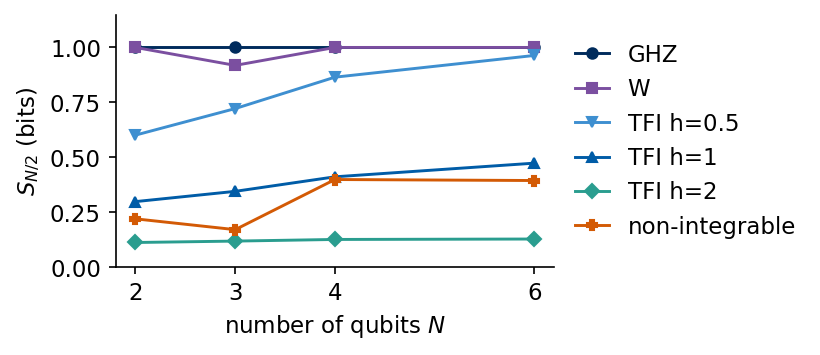

In [10]:
FAM_STYLE = {"GHZ": dict(color=UJNavy, marker="o"), "W": dict(color="#7B4FA0", marker="s"),
             "TFI h=0.5": dict(color=UJSky, marker="v"), "TFI h=1": dict(color=UJBlue, marker="^"),
             "TFI h=2": dict(color="#2A9D8F", marker="D"), "non-integrable": dict(color=DSOrange, marker="P")}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5))
    for name in TARGET_NAMES:
        ax.plot(N_LIST, [S_HALF[N][name] for N in N_LIST], ms=5, label=name, **FAM_STYLE[name])
    ax.set_xlabel("number of qubits $N$"); ax.set_ylabel(r"$S_{N/2}$ (bits)")
    ax.set_xticks(N_LIST); ax.set_ylim(0, 1.15)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.5)
    fig.tight_layout(); save(fig, "fig_lab052_entanglement"); plt.show()

The entanglement entropy is one measure of how far a target is from the product state $|0\dots0\rangle$ in which every circuit starts. The results section tests how well it predicts the difficulty of a target for the agent.

<hr/>
## 4. Gate set and exhaustive search

The agent may apply $\hat H$, $\hat S$ and $\hat T$ to any qubit and a CNOT between neighbouring qubits in either direction. For $N$ qubits this gives
$$|\mathcal A|=3N+2(N-1)=5N-2$$
gates, from 8 for two qubits to 28 for six. The set $\{\hat H,\hat T,\widehat{\mathrm{CNOT}}\}$ is universal. Every unitary on $N$ qubits can be approximated to any accuracy by a long enough circuit of these gates [M. A. Nielsen, I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press (2010), [doi:10.1017/CBO9780511976667](https://doi.org/10.1017/CBO9780511976667)]. The gate $\hat S=\hat T^2$ is redundant in principle and shortens circuits.

There are $|\mathcal A|^n$ sequences of $n$ gates. For three qubits and 13 gates this is $13^{10}\approx1.4\times10^{11}$ sequences of length 10, but many sequences lead to the same state. A breadth-first search over distinct states starts from $|0\dots0\rangle$, applies all gates to every state found in the last round and keeps only states that have not appeared before. Two vectors that differ by a global phase are the same state, so each vector is brought to a standard phase, with its first nonzero amplitude real and positive, and rounded to four decimals before the comparison. The round in which a state first appears is the length of its shortest circuit. For each target we record the best fidelity among all states reached with at most $n$ gates, $F^*(n)$, which is the exact optimum of the compilation problem at length $n$.

In [11]:
def gate_set(N):
    # the discrete gate set: H, S, T on every qubit and CNOT between neighbours in both directions
    gates = [(f"{g}{q}", U, (q,)) for g, U in (("H", H), ("S", S), ("T", T)) for q in range(N)]
    gates += [(f"CX{q}{q + 1}", CNOT, (q, q + 1)) for q in range(N - 1)]
    gates += [(f"CX{q + 1}{q}", CNOT, (q + 1, q)) for q in range(N - 1)]
    return gates

def breadth_first(N, max_len, targets):
    # rounds of new distinct states; best fidelity F*(n) with each target; shortest length with F > 0.99
    gates = gate_set(N)
    all_next = jax.jit(jax.vmap(lambda p: jnp.stack([apply_gate(p, U, q) for _, U, q in gates])))
    def keys(V):
        k = np.argmax(np.abs(V) > 1e-4, axis=1); ph = V[np.arange(len(V)), k]
        C = V * (np.abs(ph) / ph)[:, None]
        return [r.tobytes() for r in np.round(np.c_[C.real, C.imag], 4).astype(np.float32) + 0.0]
    TG = np.stack([np.asarray(v).reshape(-1) for v in targets.values()])
    front = np.asarray(zero_state(N)).reshape(1, -1)
    seen = set(keys(front)); new_per_round = [1]
    best = [np.abs(TG.conj() @ front[0]) ** 2]
    for _ in range(max_len):
        nxt = np.asarray(all_next(jnp.asarray(front.reshape((-1,) + (2,) * N)))).reshape(-1, 2 ** N)
        new = []
        for i, k in enumerate(keys(nxt)):
            if k not in seen:
                seen.add(k); new.append(i)
        front = nxt[new]; new_per_round.append(len(new))
        best.append(np.maximum(best[-1], (np.abs(front.conj() @ TG.T) ** 2).max(0)))
    best = np.array(best)                                       # shape (max_len + 1, number of targets)
    shortest = [int(np.argmax(best[:, j] > 0.99)) if (best[:, j] > 0.99).any() else None for j in range(len(TG))]
    return np.array(new_per_round), best, shortest

N_MAX = {N: 2 * N + 4 for N in N_LIST}                          # longest circuit allowed in an episode
BRUTE = {}
for N in (2, 3):
    t0 = time.time()
    rounds, best, shortest = breadth_first(N, N_MAX[N], TARGETS[N])
    # n_opt: the shortest length at which F*(n) comes within 0.005 of F*(n_max)
    n_opt = [int(np.argmax(best[:, j] >= best[-1, j] - 0.005)) for j in range(best.shape[1])]
    BRUTE[N] = dict(rounds=rounds, best=best, shortest=dict(zip(TARGETS[N], shortest)), n_opt=dict(zip(TARGETS[N], n_opt)))
    print(f"N = {N}: {len(gate_set(N))} gates, {rounds.sum()} distinct states with n <= {N_MAX[N]}"
          f" ({time.time() - t0:.1f} s), {len(gate_set(N))}^{N_MAX[N]} = {len(gate_set(N)) ** N_MAX[N]:.2e} sequences")
    for j, name in enumerate(TARGETS[N]):
        print(f"   {name:15s} F*(n_max) = {best[-1, j]:.3f} first reached with n = {n_opt[j]:2d} gates"
              f"   shortest circuit with F > 0.99: {shortest[j]}")
NUMBERS.update(NStatesThreeTen=thin(int(BRUTE[3]['rounds'].sum())),
               WThreeBest=f"{BRUTE[3]['best'][-1, 1]:.3f}")

N = 2: 8 gates, 1363 distinct states with n <= 8 (1.5 s), 8^8 = 1.68e+07 sequences
   GHZ             F*(n_max) = 1.000 first reached with n =  2 gates   shortest circuit with F > 0.99: 2
   W               F*(n_max) = 1.000 first reached with n =  5 gates   shortest circuit with F > 0.99: 5
   TFI h=0.5       F*(n_max) = 1.000 first reached with n =  6 gates   shortest circuit with F > 0.99: 6
   TFI h=1         F*(n_max) = 0.974 first reached with n =  6 gates   shortest circuit with F > 0.99: None
   TFI h=2         F*(n_max) = 0.985 first reached with n =  2 gates   shortest circuit with F > 0.99: None
   non-integrable  F*(n_max) = 0.925 first reached with n =  8 gates   shortest circuit with F > 0.99: None


N = 3: 13 gates, 68795 distinct states with n <= 10 (2.4 s), 13^10 = 1.38e+11 sequences
   GHZ             F*(n_max) = 1.000 first reached with n =  3 gates   shortest circuit with F > 0.99: 3
   W               F*(n_max) = 0.829 first reached with n = 10 gates   shortest circuit with F > 0.99: None
   TFI h=0.5       F*(n_max) = 0.886 first reached with n =  7 gates   shortest circuit with F > 0.99: None
   TFI h=1         F*(n_max) = 0.930 first reached with n = 10 gates   shortest circuit with F > 0.99: None
   TFI h=2         F*(n_max) = 0.969 first reached with n =  3 gates   shortest circuit with F > 0.99: None
   non-integrable  F*(n_max) = 0.769 first reached with n = 10 gates   shortest circuit with F > 0.99: None


For two qubits the exhaustive search finds circuits with $F>0.99$ for the GHZ state, the W state and the transverse-field ground state at $h=0.5$, the last one with six gates. For three qubits only the GHZ state is reached with $F>0.99$ within $n_{\max}=10$ gates, and the best fidelity of the W state is $0.829$. These exact values are the reference for the agents.

The left panel compares the number $|\mathcal A|^n$ of gate sequences with the number of distinct states they reach, for two and three qubits. Both grow exponentially, but the number of distinct states grows far more slowly. The right panel shows the exact best fidelity $F^*(n)$ for the six three-qubit targets. The GHZ state is reached exactly with three gates. The transverse-field ground state at $h=2$ comes close after a few gates, while the W state and the non-integrable ground state stay well below $F=1$ within $n_{\max}=10$ gates.

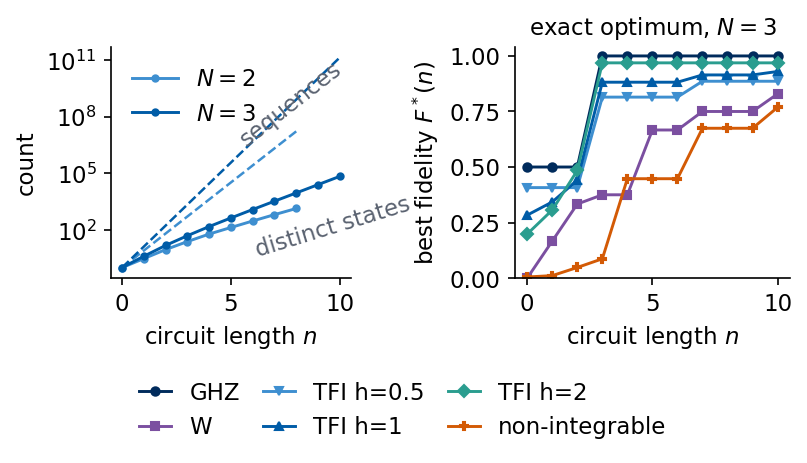

In [12]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 3.1), gridspec_kw=dict(width_ratios=[1, 1.15]))
    ax = axs[0]
    for N, col in ((2, UJSky), (3, UJBlue)):
        n = np.arange(N_MAX[N] + 1); A = len(gate_set(N))
        ax.semilogy(n, float(A) ** n, ls="--", color=col, lw=1.2)
        ax.semilogy(n, np.cumsum(BRUTE[N]["rounds"]), "o-", ms=3, color=col, label=f"$N={N}$")
    ax.text(5.2, 3e6, "sequences", fontsize=11, color=UJGray, rotation=38)
    ax.text(6.0, 4, "distinct states", fontsize=11, color=UJGray, rotation=17)
    ax.set_xlabel("circuit length $n$"); ax.set_ylabel("count"); ax.legend(loc="upper left")
    ax = axs[1]
    for j, name in enumerate(TARGETS[3]):
        ax.plot(np.arange(N_MAX[3] + 1), BRUTE[3]["best"][:, j], ms=4, label=name, **FAM_STYLE[name])
    ax.set_xlabel("circuit length $n$"); ax.set_ylabel(r"best fidelity $F^*(n)$"); ax.set_title("exact optimum, $N=3$")
    ax.set_ylim(0, 1.04)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=11, handlelength=1.4,
               bbox_to_anchor=(0.5, -0.01), columnspacing=1.0)
    fig.tight_layout(rect=(0, 0.17, 1, 1)); save(fig, "fig_lab052_counts"); plt.show()

The exhaustive search is possible here only because two and three qubits give a few tens of thousands of distinct states. The number of gates, $5N-2$, and the number of amplitudes, $2^N$, both grow with $N$, and for the longer chains only the GHZ state keeps an exact reference.

<hr/>
## 5. Compilation as a reinforcement-learning problem

In reinforcement learning an agent builds the circuit one gate at a time and learns from rewards which gate to choose. The target and the initial state are fixed for one agent, and a separate agent is trained for every target. We define the four ingredients of the Markov decision process.

The **state** at step $t$ is the current state vector $|\psi_t\rangle$. A neural network takes real numbers as input, so the vector, brought to the standard global phase, is written as its $2^N$ real parts and $2^N$ imaginary parts,
$$s_t=\big(\mathrm{Re}\,\psi_t,\ \mathrm{Im}\,\psi_t\big)\in\mathbb R^{2^{N+1}}.$$
This input is the full quantum state, which a simulation provides. On hardware the state is not observable, and the agent would have to work with measured quantities.

The **action** $a_t\in\mathcal A$ is one of the $5N-2$ gates, and the environment applies it, $|\psi_{t+1}\rangle=\hat U_{a_t}|\psi_t\rangle$. This transition is deterministic.

The **reward** can be defined in two ways. The plain choice rewards only the final fidelity $F_n$ of the finished circuit of $n$ gates,
$$r_{t+1}^{\rm final}=\begin{cases}F_{t+1} & \text{if the episode ends after gate } t,\\ 0 & \text{otherwise},\end{cases}\qquad F_t=|\langle\psi_{\rm target}|\psi_t\rangle|^2 .$$
This signal is sparse. An unsuccessful circuit still gives information through its terminal fidelity, while credit assignment over its earlier gates remains difficult. We instead reward every gain in fidelity and charge a fixed cost $\zeta$ per gate,
$$r_{t+1}=F_{t+1}-F_t-\zeta .$$
The fidelity gains of an episode of $n$ gates add up to $F_n-F_0$, so the undiscounted return
$$G=\sum_{t=0}^{n-1}r_{t+1}=F_n-F_0-\zeta n$$
differs from the final-fidelity reward only by the constant $F_0$ and by the gate cost. For the undiscounted return the two choices have the same best circuits when $\zeta=0$, while discounting also weights intermediate fidelities and can change their ranking. The shaped reward tells the agent after every gate whether it moved towards the target. The cost $\zeta=0.01$ favours the shorter of two circuits with equal fidelity.

An **episode** starts at $|0\dots0\rangle$ and ends with success as soon as $F>0.99$, or after $n_{\max}=2N+4$ gates. The end at $n_{\max}$ is a time limit of the simulation, so the value of the last state is still taken into account in the learning target below.

The next cell writes the environment as pure functions of the state tensor, so that JAX can compile them and run many episodes at once. We check it on the GHZ circuit of three qubits, whose return must equal $F_n-F_0-3\zeta=1-0.5-0.03=0.47$.

In [13]:
ZETA, GAMMA, F_SUCCESS = 0.01, 0.95, 0.99

def make_env(N):
    # the compilation environment for N qubits: pure functions of the state, jit- and vmap-compatible
    gates = gate_set(N)
    branches = [lambda p, U=U, q=q: apply_gate(p, U, q) for _, U, q in gates]
    def apply_action(psi, a):
        # apply gate number a (a traced integer) to the state tensor psi
        return jax.lax.switch(a, branches, psi)
    def observe(psi):
        # real network input: Re and Im of the state with its first nonzero amplitude made real and positive
        v = psi.reshape(-1)
        k = jnp.argmax(jnp.abs(v) > 1e-4)
        c = v * (jnp.abs(v[k]) / v[k])
        return jnp.concatenate([c.real, c.imag])
    def measured_fidelity(F, shots, key):
        # estimate of F from `shots` projective measurements in the target basis: k ~ Binomial(shots, F), F_hat = k/shots
        # shots = 0 returns the exact F
        k = jax.random.binomial(key, jnp.maximum(shots, 1).astype(jnp.float32), jnp.clip(F, 0.0, 1.0))
        return jnp.where(shots > 0, k / jnp.maximum(shots, 1), F)
    def step(psi, a, target, last=False, zeta=ZETA, final_only=False, shots=0, key=None):
        # one gate: new state, reward, success flag F_{t+1} > 0.99 (decided with the exact fidelity)
        #   final_only = False: r = F_{t+1} - F_t - zeta         (fidelity gain, the default)
        #   final_only = True:  r = F_{t+1} at the end of the episode, else 0, minus zeta
        #   last = True when this gate is the n_max-th gate of the episode
        #   shots > 0: the fidelities in the reward are estimated from that many measurements
        #   zeta: the gate cost, a number or an array with one cost per gate of the gate set
        psi2 = apply_action(psi, a)
        f0, f1 = fidelity_pure(target, psi), fidelity_pure(target, psi2)
        success = f1 > F_SUCCESS
        if key is not None:
            k0, k1 = jax.random.split(key)
            f0, f1 = measured_fidelity(f0, shots, k0), measured_fidelity(f1, shots, k1)
        r_final = jnp.where(success | last, f1, 0.0)
        cost = zeta[a] if jnp.ndim(zeta) == 1 else zeta              # one cost per gate, or the same for all
        r = jnp.where(final_only, r_final, f1 - f0) - cost
        return psi2, r, success
    return dict(N=N, gate_names=[g for g, _, _ in gates], n_actions=len(gates), n_obs=2 * 2 ** N,
                n_max=N_MAX[N], psi0=zero_state(N), apply_action=apply_action, observe=observe, step=step)

# check the environment on the GHZ circuit H0, CX01, CX12 for three qubits
env3 = make_env(3)
psi, total = env3["psi0"], 0.0
for g in ["H0", "CX01", "CX12"]:
    psi, r, done = env3["step"](psi, env3["gate_names"].index(g), TARGETS[3]["GHZ"])
    total += float(r)
    print(f"{g:5s} reward {float(r):+.3f}   success {bool(done)}")
print(f"return {total:.3f} = F_n - F_0 - 3 zeta = {1.0 - 0.5 - 3 * ZETA:.3f}")

H0    reward -0.260   success False
CX01  reward -0.010   success False
CX12  reward +0.740   success True
return 0.470 = F_n - F_0 - 3 zeta = 0.470


The rewards along the GHZ circuit show a property of this task that matters for learning. The Hadamard gate lowers the fidelity from $1/2$ to $1/4$, the first CNOT keeps it at $1/4$, and only the last CNOT raises it to 1. The agent must accept a loss and a plateau of zero gains before the reward arrives. For $N$ qubits the plateau lasts $N-2$ CNOTs, so it grows with $N$.

<hr/>
## 6. Deep Q-learning

Q-learning assigns to every state $s$ and action $a$ the expected discounted return $Q(s,a)$ when gate $a$ is applied in state $s$ and the best gates follow. The optimal action values obey the Bellman equation
$$Q^*(s,a)=r(s,a)+\gamma\max_{a'}Q^*(s',a'),$$
with the next state $s'$ and the discount factor $\gamma=0.95$. A table of $Q$ would need one entry for every reachable state, and with the $\hat T$ gate this set is already in the tens of thousands for three qubits and grows without bound with the circuit length. Deep Q-learning replaces the table by a neural network $Q_\theta(s,a)$ that takes the $2^{N+1}$ real numbers of $s$ and returns $5N-2$ numbers, one action value per gate. The agent applies the gate with the largest output. The network has two hidden layers of 128 units with the rectified linear activation $\mathrm{ReLU}(x)=\max(0,x)$. The next cell defines it and counts its parameters for every chain length.

In [14]:
N_HIDDEN = 128

def init_qnet(key, sizes):
    # weights with variance 2/fan_in (He initialisation), zero biases; params = [(W, b), ...]
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, k = jax.random.split(key)
        params.append((jax.random.normal(k, (n_in, n_out)) * jnp.sqrt(2.0 / n_in), jnp.zeros(n_out)))
    return params

def qnet(params, x):
    # Q_theta(s, .) for a batch of inputs x: ReLU hidden layers, linear output layer
    for W, b in params[:-1]:
        x = jax.nn.relu(x @ W + b)
    W, b = params[-1]
    return x @ W + b

for N in N_LIST:
    e = make_env(N)
    n_par = sum(w.size + b.size for w, b in init_qnet(jax.random.PRNGKey(0), [e["n_obs"], N_HIDDEN, N_HIDDEN, e["n_actions"]]))
    print(f"N = {N}: {e['n_obs']:3d} inputs, {e['n_actions']:2d} outputs, {n_par:6d} parameters")

N = 2:   8 inputs,  8 outputs,  18696 parameters


N = 3:  16 inputs, 13 outputs,  20365 parameters


N = 4:  32 inputs, 18 outputs,  23058 parameters


N = 6: 128 inputs, 28 outputs,  36636 parameters


The number of parameters grows mainly through the input layer, from 8 inputs for two qubits to 128 inputs for six. The drawing shows the architecture for two qubits, with eight of the 128 units of each hidden layer drawn.

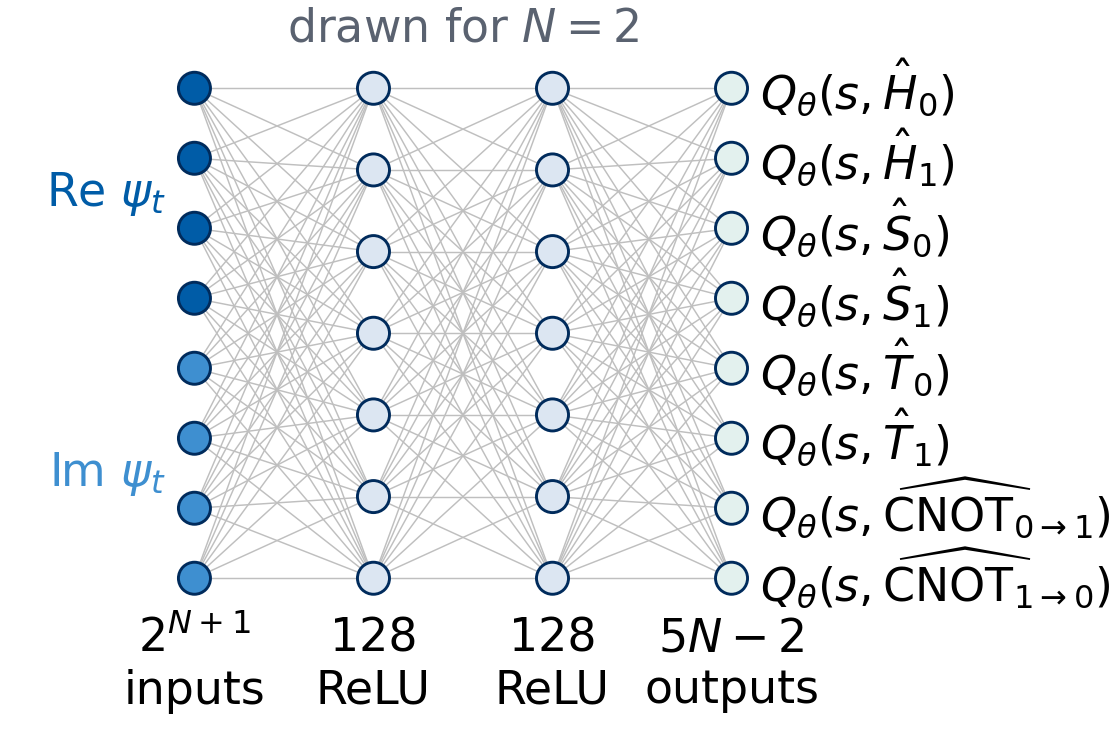

In [15]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 3.1))
    xs, n_draw = [0.0, 1.9, 3.8, 5.7], [8, 7, 7, 8]
    ys = [np.linspace(2.6, -2.6, n) for n in n_draw]
    for l in range(3):
        for y1 in ys[l]:
            for y2 in ys[l + 1]:
                ax.plot([xs[l], xs[l + 1]], [y1, y2], color="0.75", lw=0.35, zorder=1)
    for l, (x, yy) in enumerate(zip(xs, ys)):
        for i, y in enumerate(yy):
            fc = (UJBlue if i < 4 else UJSky) if l == 0 else ("#DCE6F2" if l < 3 else "#E3F1EE")
            ax.add_patch(Circle((x, y), 0.17, fc=fc, ec=UJNavy, lw=0.7, zorder=3))
    ax.text(-0.3, ys[0][:4].mean(), r"Re $\psi_t$", ha="right", va="center", color=UJBlue)
    ax.text(-0.3, ys[0][4:].mean(), r"Im $\psi_t$", ha="right", va="center", color=UJSky)
    for y, g in zip(ys[3], [r"$\hat H_0$", r"$\hat H_1$", r"$\hat S_0$", r"$\hat S_1$", r"$\hat T_0$", r"$\hat T_1$", r"$\widehat{\mathrm{CNOT}}_{0\to1}$", r"$\widehat{\mathrm{CNOT}}_{1\to0}$"]):
        ax.text(xs[3] + 0.3, y, r"$Q_\theta(s,$" + g + r"$)$", ha="left", va="center")
    for x, t in [(xs[0], "$2^{N+1}$\ninputs"), (xs[1], "128\nReLU"), (xs[2], "128\nReLU"), (xs[3], "$5N-2$\noutputs")]:
        ax.text(x, -3.0, t, ha="center", va="top")
    ax.text(2.85, 3.0, "drawn for $N=2$", ha="center", va="bottom", color=UJGray)
    ax.set_xlim(-2.0, 8.6); ax.set_ylim(-4.2, 3.4); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab052_qnet"); plt.show()

### The DQN target

Training moves the network output $Q_\theta(s_t,a_t)$ towards the right-hand side of the Bellman equation evaluated with a network,
$$y_t^{\rm DQN}=r_{t+1}+\gamma\,(1-d_{t+1})\max_{a'}Q_{\bar\theta}(s_{t+1},a'),$$
where $d_{t+1}=1$ when the step reached the target and the episode ends there. The loss is the Huber function of $Q_\theta(s_t,a_t)-y_t$, quadratic for small and linear for large differences, minimised by the Adam optimiser. Two devices make this regression stable. Past transitions $(s_t,a_t,r_{t+1},s_{t+1},d_{t+1})$ are stored in a replay memory, and the network learns from random batches drawn from it, which breaks the correlation between consecutive steps of one episode. The values $y_t$ are computed with a target network $Q_{\bar\theta}$, a copy of $Q_\theta$ that is refreshed only every 250 updates, so that the regression target does not move with every gradient step.

### Overestimation and the DDQN target

The maximum in $y_t^{\rm DQN}$ is taken over estimates that contain noise, and the maximum of noisy numbers is biased upwards. If all $|\mathcal A|$ actions have the same true value $Q$ and each estimate carries an independent error of standard deviation $\sigma$, then $\mathbb E\max_a\tilde Q(s,a)>Q$, and the bias grows with the number of actions. The bias enters the target, is learned by the network and is passed on to earlier states. Double Q-learning separates the choice of the best action from its evaluation. The online network chooses the action and the target network evaluates it,
$$\begin{aligned}a^*&=\arg\max_{a'}Q_\theta(s_{t+1},a'),\\ y_t^{\rm DDQN}&=r_{t+1}+\gamma\,(1-d_{t+1})\,Q_{\bar\theta}(s_{t+1},a^*).\end{aligned}$$
When the errors of the two networks are independent, the error of $Q_{\bar\theta}(s_{t+1},a^*)$ is uncorrelated with the choice of $a^*$, and the upward bias disappears. When the true values differ, this double estimator can instead underestimate slightly [H. van Hasselt, Adv. Neural Inf. Process. Syst. **23** (2010), <https://papers.nips.cc/paper_files/paper/2010/hash/091d584fced301b442654dd8c23b3fc9-Abstract.html>]. The two networks of DDQN are only partly independent, because the target network is an older copy of the online network, so the bias is reduced and part of it remains. The cell below shows the effect with Gaussian noise of unit standard deviation on equal true values $Q=0$.

|A| =  8:  E max = 1.420 sigma   double estimator = -0.008 sigma
|A| = 13:  E max = 1.670 sigma   double estimator = +0.006 sigma
|A| = 18:  E max = 1.822 sigma   double estimator = +0.003 sigma
|A| = 28:  E max = 2.015 sigma   double estimator = +0.005 sigma
|A| = 38:  E max = 2.142 sigma   double estimator = +0.005 sigma


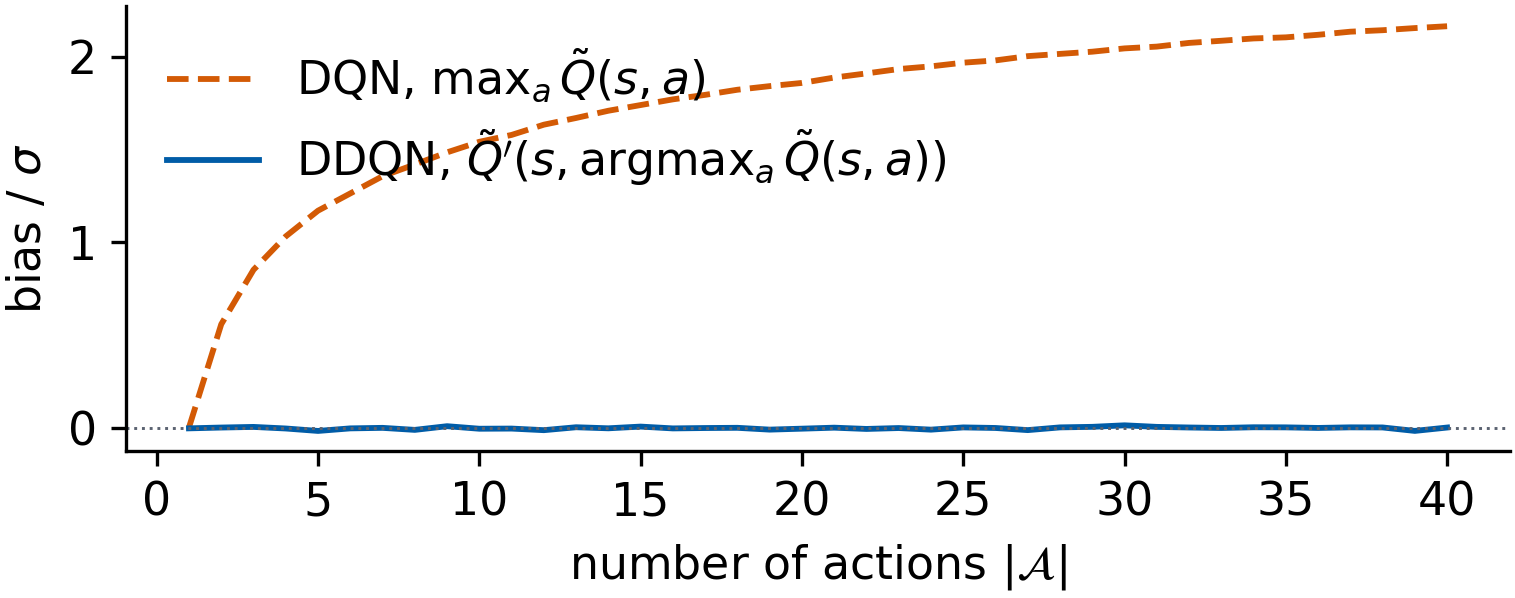

In [16]:
rng = np.random.default_rng(0)
n_acts = np.arange(1, 41); n_samp = 20_000
bias_max, bias_double = [], []
for A in n_acts:
    qa, qb = rng.normal(size=(n_samp, A)), rng.normal(size=(n_samp, A))     # two independent noisy estimates
    bias_max.append(qa.max(1).mean())                                       # single estimator: max_a Q_a
    bias_double.append(qb[np.arange(n_samp), qa.argmax(1)].mean())          # double: choose with a, evaluate with b
bias_max, bias_double = np.array(bias_max), np.array(bias_double)
for A in (8, 13, 18, 28, 38):
    print(f"|A| = {A:2d}:  E max = {bias_max[A - 1]:.3f} sigma   double estimator = {bias_double[A - 1]:+.3f} sigma")
NUMBERS.update(BiasEight=f"{bias_max[7]:.2f}", BiasThirtyEight=f"{bias_max[37]:.2f}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3))
    ax.plot(n_acts, bias_max, color=DSOrange, ls="--", label=r"DQN, $\mathrm{max}_a\,\tilde Q(s,a)$")
    ax.plot(n_acts, bias_double, color=UJBlue, label=r"DDQN, $\tilde Q'(s,\mathrm{argmax}_a\,\tilde Q(s,a))$")
    ax.axhline(0, color=UJGray, lw=0.7, ls=":")
    ax.set_xlabel(r"number of actions $|\mathcal{A}|$"); ax.set_ylabel(r"bias / $\sigma$")
    ax.legend(loc="upper left")
    fig.tight_layout(); save(fig, "fig_lab052_overestimation"); plt.show()

For 8 actions the maximum of the noisy estimates exceeds the true value by $1.42\,\sigma$, and for 38 actions by $2.14\,\sigma$, while the double estimator stays at zero within the sampling error. The larger the gate set, the larger the bias of the DQN target in this model.

One transition shows the two targets side by side. We take an untrained network as the online network $Q_\theta$, a second untrained network as the target network $Q_{\bar\theta}$, and the transition in which $\hat H_0$ is applied to $|00\rangle$ with the Bell state as target. The next state is $s_1=|{+}0\rangle$, the reward is $r_1=F_1-F_0-\zeta=0.25-0.5-0.01$, and the episode does not end.

In [17]:
def td_target(params, params_tgt, r, s2, done, gamma, double):
    # DQN:  y = r + gamma (1-d) max_a' Q_tgt(s', a')
    # DDQN: y = r + gamma (1-d) Q_tgt(s', argmax_a' Q(s', a'))
    q_tgt = qnet(params_tgt, s2)
    a_star = jnp.where(double, jnp.argmax(qnet(params, s2), 1), jnp.argmax(q_tgt, 1))
    return r + gamma * (1.0 - done) * jnp.take_along_axis(q_tgt, a_star[:, None], 1)[:, 0]

env2 = make_env(2)
params_online = init_qnet(jax.random.PRNGKey(10), [env2["n_obs"], N_HIDDEN, N_HIDDEN, env2["n_actions"]])
params_target = init_qnet(jax.random.PRNGKey(11), [env2["n_obs"], N_HIDDEN, N_HIDDEN, env2["n_actions"]])
bell = ghz_state(2)
s1_state, r1, done0 = env2["step"](env2["psi0"], env2["gate_names"].index("H0"), bell)
s1 = env2["observe"](s1_state)[None, :]
print(f"r_1 = {float(r1):+.3f}, episode ends: {bool(done0)}")
print("Q_target(s_1, a) =", np.asarray(qnet(params_target, s1)[0]).round(3))
print("Q_online(s_1, a) =", np.asarray(qnet(params_online, s1)[0]).round(3))
for double, name in ((False, "DQN "), (True, "DDQN")):
    y = td_target(params_online, params_target, jnp.array([r1]), s1, jnp.array([0.0]), GAMMA, double)
    print(f"{name} target y_0 = {float(y[0]):+.4f}")

r_1 = -0.260, episode ends: False


Q_target(s_1, a) = [-0.416 -0.48   0.356  1.001  0.017  0.06  -0.31   0.175]
Q_online(s_1, a) = [-1.104  0.016  0.99   0.5   -0.299 -0.027 -0.194  0.613]


DQN  target y_0 = +0.6906
DDQN target y_0 = +0.0781


The online network ranks the gates in the next state $s_1$ and prefers $\hat S_0$, the third output, with $Q_\theta(s_1,\hat S_0)=0.99$. The target network gives this gate the value $0.356$, while its own largest value, $1.001$, belongs to $\hat S_1$. DQN therefore takes $y_0=-0.260+0.95\cdot1.001=0.691$ and DDQN takes $y_0=-0.260+0.95\cdot0.356=0.078$. DQN always takes the largest value of $Q_{\bar\theta}$, so its target is never below the DDQN target, and the difference is the part of the maximum that comes from the choice of the action.

<hr/>
## 7. Training

The agent and the training loop are written as pure functions. The function `td_target` of the worked transition computes the DQN or the DDQN target, and the flag `double` selects between them, so that both algorithms share all other code. `make_trainer` returns a function `train(key, target, double, zeta, final_only, shots)` that runs a whole training in one `jax.lax.scan` and records the greedy circuit at regular intervals.

During training the agent explores. With probability $\epsilon$ it applies a random gate and otherwise the gate with the largest $Q_\theta$, and $\epsilon$ decreases linearly from 1 to $0.05$ over the first 60% of the updates. Thirty-two episodes run side by side, and after every step of all of them the network is updated once on a batch of 128 transitions drawn from the replay memory. Every 500 updates we record the greedy circuit, in which the agent always applies the gate with the largest $Q_\theta$, for $n_{\max}$ gates from $|0\dots0\rangle$, together with the fidelity after each of its gates and the predicted value $\max_aQ_\theta(s_0,a)$ of the initial state.

In [18]:
CFG = dict(n_updates=10_000, n_env=32, capacity=20_000, batch=128, lr=1e-3, gamma=GAMMA, hidden=N_HIDDEN,
           warmup=1_000, target_every=250, eval_every=500, eps_end=0.05, eps_frac=0.6)

def make_trainer(env, cfg):
    A, D, N, n_max = env["n_actions"], env["n_obs"], env["N"], env["n_max"]
    opt = optax.adam(cfg["lr"])
    v_observe = jax.vmap(env["observe"])
    v_step = jax.vmap(env["step"], (0, 0, None, 0, None, None, None, 0))

    def loss_fn(params, params_tgt, batch, double):
        s, a, r, s2, d = batch
        y = jax.lax.stop_gradient(td_target(params, params_tgt, r, s2, d, cfg["gamma"], double))
        q = jnp.take_along_axis(qnet(params, s), a[:, None], 1)[:, 0]
        return optax.huber_loss(q, y).mean()

    def greedy_circuit(params, target):
        # n_max gates chosen greedily from |0...0>: fidelity after every gate, the gates, max_a Q(s_0, a)
        def body(psi, _):
            a = jnp.argmax(qnet(params, env["observe"](psi)))
            psi2 = env["apply_action"](psi, a)
            return psi2, (fidelity_pure(target, psi2), a)
        _, (fids, acts) = jax.lax.scan(body, env["psi0"], None, length=n_max)
        return fids, acts, jnp.max(qnet(params, env["observe"](env["psi0"])))

    def train(key, target, double, zeta=ZETA, final_only=False, shots=0):
        n_env, cap, n_upd = cfg["n_env"], cfg["capacity"], cfg["n_updates"]
        key, k = jax.random.split(key)
        params = init_qnet(k, [D, cfg["hidden"], cfg["hidden"], A])
        params_tgt, opt_state = params, opt.init(params)
        memory = (jnp.zeros((cap, D)), jnp.zeros(cap, jnp.int32), jnp.zeros(cap), jnp.zeros((cap, D)), jnp.zeros(cap))
        psi = jnp.broadcast_to(env["psi0"], (n_env,) + env["psi0"].shape)
        steps = jnp.zeros(n_env, jnp.int32)

        def update(carry, u):
            params, params_tgt, opt_state, memory, n_stored, psi, steps, key, n_ep = carry
            key, k_explore, k_action, k_batch, k_shots = jax.random.split(key, 5)
            # act: epsilon-greedy gates in all n_env episodes
            eps = jnp.maximum(cfg["eps_end"], 1.0 - (1.0 - cfg["eps_end"]) * u / (cfg["eps_frac"] * n_upd))
            s = v_observe(psi)
            a = jnp.where(jax.random.uniform(k_explore, (n_env,)) < eps,
                          jax.random.randint(k_action, (n_env,), 0, A), jnp.argmax(qnet(params, s), 1))
            psi2, r, success = v_step(psi, a, target, steps + 1 >= n_max, zeta, final_only, shots,
                                      jax.random.split(k_shots, n_env))
            steps = steps + 1
            # store the transitions in the replay memory (a ring buffer)
            new = (s, a, r, v_observe(psi2), success.astype(jnp.float32))
            pos = (u * n_env) % cap
            memory = tuple(jax.lax.dynamic_update_slice_in_dim(m, x, pos, 0) for m, x in zip(memory, new))
            n_stored = jnp.minimum(n_stored + n_env, cap)
            # finished episodes (success or time limit) restart from |0...0>
            end = success | (steps >= n_max)
            n_ep = n_ep + end.sum()
            psi = jnp.where(end.reshape((-1,) + (1,) * N), env["psi0"], psi2)
            steps = jnp.where(end, 0, steps)
            # learn: one gradient step on a random batch, after the warm-up
            j = jax.random.randint(k_batch, (cfg["batch"],), 0, n_stored)
            grads = jax.grad(loss_fn)(params, params_tgt, tuple(m[j] for m in memory), double)
            upd, opt_state_new = opt.update(grads, opt_state, params)
            go = n_stored >= cfg["warmup"]
            params = jax.tree.map(lambda x, y: jnp.where(go, y, x), params, optax.apply_updates(params, upd))
            opt_state = jax.tree.map(lambda x, y: jnp.where(go, y, x), opt_state, opt_state_new)
            params_tgt = jax.tree.map(lambda x, y: jnp.where(u % cfg["target_every"] == 0, y, x), params_tgt, params)
            return (params, params_tgt, opt_state, memory, n_stored, psi, steps, key, n_ep), None

        def block(carry, i):
            carry, _ = jax.lax.scan(update, carry, i * cfg["eval_every"] + jnp.arange(cfg["eval_every"]))
            fids, acts, q0 = greedy_circuit(carry[0], target)
            return carry, (fids, acts, q0, carry[-1])

        carry = (params, params_tgt, opt_state, memory, 0, psi, steps, key, 0)
        _, logs = jax.lax.scan(block, carry, jnp.arange(n_upd // cfg["eval_every"]))
        return logs
    return train

For each chain length we train one agent for every combination of the six targets, the two algorithms and three seeds. The 36 trainings of one chain length run as one compiled program, with `jax.vmap` over the runs on one device and `jax.pmap` over the CPU cores. The seed fixes the initial network and the exploration, and the DQN and DDQN agents with the same seed and target start from the same network.

In [19]:
ALGOS, SEEDS = ["DQN", "DDQN"], [0, 1, 2]
RUNS = [(name, algo, seed) for name in TARGET_NAMES for algo in ALGOS for seed in SEEDS]
n_dev = max(d for d in range(1, len(jax.devices()) + 1) if len(RUNS) % d == 0)
LOGS, T_TRAIN = {}, {}
for N in N_LIST:
    env = make_env(N)
    train_all = jax.pmap(jax.vmap(make_trainer(env, CFG)))
    keys = jnp.stack([jax.random.PRNGKey(100 * N + 10 * TARGET_NAMES.index(n) + s) for n, _, s in RUNS])
    tgts = jnp.stack([TARGETS[N][n] for n, _, _ in RUNS])
    dbl = jnp.array([a == "DDQN" for _, a, _ in RUNS])
    shard = lambda x: x.reshape((n_dev, -1) + x.shape[1:])
    t0 = time.time()
    zeta_all, final_all = jnp.full(len(RUNS), ZETA), jnp.zeros(len(RUNS), bool)
    shots_all = jnp.zeros(len(RUNS), jnp.int32)
    logs = jax.block_until_ready(train_all(shard(keys), shard(tgts), shard(dbl), shard(zeta_all), shard(final_all),
                                           shard(shots_all)))
    T_TRAIN[N] = time.time() - t0
    fids, acts, q0, n_ep = (np.asarray(x).reshape((len(RUNS),) + x.shape[2:]) for x in logs)
    LOGS[N] = dict(fids=fids, acts=acts, q0=q0, episodes=n_ep)
    print(f"N = {N}: {len(RUNS)} trainings on {n_dev} devices in {T_TRAIN[N]:.0f} s")

N = 2: 36 trainings on 12 devices in 87 s


N = 3: 36 trainings on 12 devices in 88 s


N = 4: 36 trainings on 12 devices in 108 s


N = 6: 36 trainings on 12 devices in 166 s


The training time grows with $N$ through the cost of a gate on $2^N$ amplitudes and through the size of the network input. The times were measured on a machine shared with other jobs and vary between runs.

<hr/>
## 8. Trained agents

Every recorded greedy circuit is cut where its fidelity is largest, since the environment reports the fidelity after every gate. Its fidelity there is $F_{\rm agent}$ and its length $n_{\rm agent}$. A run is a success when $F_{\rm agent}>0.99$. The cell below collects these numbers for the circuits after the last update, together with the number of training episodes until the greedy circuit first reached $F>0.99$.

In [20]:
def circuit_summary(fids_row):
    # best fidelity along a greedy circuit and the first gate count at which it is reached
    k = int(np.argmax(fids_row >= fids_row.max() - 1e-4))
    return float(fids_row[k]), k + 1

RES = {}                                                         # RES[N][(target, algo)] = per-seed arrays
for N in N_LIST:
    RES[N] = {}
    for name in TARGET_NAMES:
        for algo in ALGOS:
            idx = [i for i, r in enumerate(RUNS) if r[0] == name and r[1] == algo]
            F, n, ep_hit = [], [], []
            for i in idx:
                f_last, n_last = circuit_summary(LOGS[N]["fids"][i, -1])
                F.append(f_last); n.append(n_last)
                hit = np.nonzero(LOGS[N]["fids"][i].max(1) > F_SUCCESS)[0]
                ep_hit.append(int(LOGS[N]["episodes"][i, hit[0]]) if len(hit) else None)
            F_ref = BRUTE[N]["best"][-1, TARGET_NAMES.index(name)] if N in BRUTE else np.nan
            RES[N][(name, algo)] = dict(F=np.array(F), n=np.array(n), episodes_to_success=ep_hit,
                                        success=np.array(F) > F_SUCCESS, at_optimum=np.array(F) >= F_ref - 0.005)

for N in N_LIST:
    print(f"N = {N}")
    for name in TARGET_NAMES:
        ref = ""
        if N in BRUTE:
            j = TARGET_NAMES.index(name)
            ref = f"   exact F*(n_max) = {BRUTE[N]['best'][-1, j]:.3f}, shortest = {BRUTE[N]['shortest'][name]}"
        elif name == "GHZ":
            ref = f"   exact shortest = {N}"
        line = "  ".join(f"{a}: F = {np.round(RES[N][(name, a)]['F'], 3)} n = {RES[N][(name, a)]['n']}" for a in ALGOS)
        print(f"  {name:15s} {line}{ref}")

N = 2
  GHZ             DQN: F = [0.5 0.5 0.5] n = [2 2 1]  DDQN: F = [1. 1. 1.] n = [2 2 2]   exact F*(n_max) = 1.000, shortest = 2
  W               DQN: F = [0.5   0.854 0.854] n = [2 6 6]  DDQN: F = [1.    0.854 0.854] n = [7 6 6]   exact F*(n_max) = 1.000, shortest = 5
  TFI h=0.5       DQN: F = [0.854 0.854 0.854] n = [2 2 2]  DDQN: F = [0.854 0.854 0.854] n = [2 2 2]   exact F*(n_max) = 1.000, shortest = 6
  TFI h=1         DQN: F = [0.947 0.947 0.947] n = [2 2 2]  DDQN: F = [0.947 0.362 0.947] n = [2 1 2]   exact F*(n_max) = 0.974, shortest = None
  TFI h=2         DQN: F = [0.985 0.985 0.985] n = [2 2 2]  DDQN: F = [0.985 0.985 0.985] n = [2 2 2]   exact F*(n_max) = 0.985, shortest = None
  non-integrable  DQN: F = [0.905 0.905 0.905] n = [8 8 8]  DDQN: F = [0.9   0.767 0.767] n = [5 8 8]   exact F*(n_max) = 0.925, shortest = None
N = 3
  GHZ             DQN: F = [1.  1.  0.5] n = [3 3 1]  DDQN: F = [1. 1. 1.] n = [3 3 3]   exact F*(n_max) = 1.000, shortest = 3
  W            

The table shows the final fidelity $F_{\rm agent}$ and the gate count $n_{\rm agent}$ of every seed. For the transverse-field ground state at $h=2$, 21 of the 24 agents find the circuit of one Hadamard gate per qubit, which for $N\le3$ is also the exact optimum. At $h=1$ the agents mostly find the same circuit, whose fidelity lies below the exact optimum, and the exhaustive search finds better circuits only with at least 6 gates for $N=2$ and 7 gates for $N=3$. The GHZ state is reached by the three DDQN agents for $N=2$, by five of the six agents for $N=3$, by four of six for $N=4$ and by two of six for $N=6$. The W state and the ferromagnetic ground state at $h=0.5$ stay well below the exact optimum for most seeds. For the non-integrable ground state at $N=6$ no agent exceeds $F=0.3$.

The first figure follows the training for three targets of three qubits, the GHZ state, the transverse-field ground state at $h=1$ and the non-integrable ground state. It shows the fidelity $F_{\rm agent}$ of the greedy circuit against the number of training episodes, averaged over the three seeds, with the band between the lowest and the highest seed. Training runs for a fixed number of $10^4$ updates, and every update follows one gate in each of the 32 episodes that run side by side. An episode lasts at most $n_{\max}$ gates and ends earlier when it reaches the target, so the number of episodes within the $10^4$ updates differs between targets, and the cell prints it for every target and algorithm. The dotted line is the exact best fidelity $F^*(n_{\max})$ from the exhaustive search.

GHZ             DQN   37,466 episodes in 10,000 updates
GHZ             DDQN  68,929 episodes in 10,000 updates
TFI h=1         DQN   32,000 episodes in 10,000 updates
TFI h=1         DDQN  32,000 episodes in 10,000 updates
non-integrable  DQN   32,000 episodes in 10,000 updates
non-integrable  DDQN  32,000 episodes in 10,000 updates


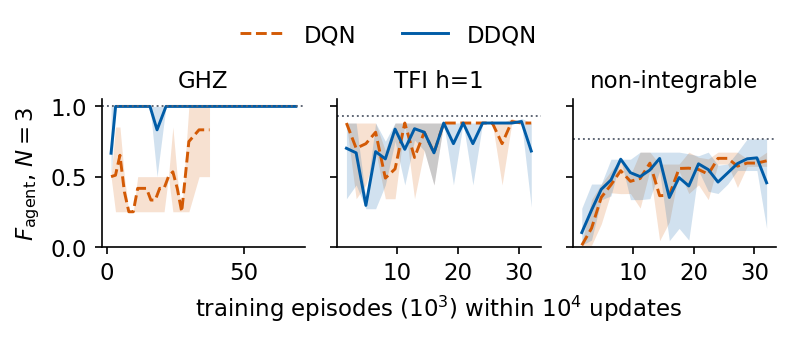

In [21]:
N_SHOW, SHOW = 3, ["GHZ", "TFI h=1", "non-integrable"]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.3), sharey=True)
    for ax, name in zip(axs, SHOW):
        for algo in ALGOS:
            idx = [i for i, r in enumerate(RUNS) if r[0] == name and r[1] == algo]
            Fc = np.array([[circuit_summary(row)[0] for row in LOGS[N_SHOW]["fids"][i]] for i in idx])
            ep = LOGS[N_SHOW]["episodes"][idx].mean(0) / 1e3
            ax.fill_between(ep, Fc.min(0), Fc.max(0), color=ALGO_STYLE[algo]["color"], alpha=0.18, lw=0)
            ax.plot(ep, Fc.mean(0), label=algo, **ALGO_STYLE[algo])
            print(f"{name:15s} {algo:5s} {LOGS[N_SHOW]['episodes'][idx, -1].mean():,.0f} episodes in {CFG['n_updates']:,} updates")
        ax.axhline(BRUTE[N_SHOW]["best"][-1, TARGET_NAMES.index(name)], color=UJGray, lw=0.9, ls=":")
        ax.set_title(name)
    axs[0].set_ylabel(r"$F_{\rm agent}$, $N=3$"); axs[0].set_ylim(0, 1.05)
    axs[1].set_xlabel(r"training episodes ($10^3$) within $10^4$ updates")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.88)); save(fig, "fig_lab052_learning"); plt.show()

For the GHZ state all three DDQN agents and two of the three DQN agents reach $F=1$, with a wide spread between seeds early in the training. For the transverse-field ground state at $h=1$ the agents settle on the Hadamard circuit and stay below the exact optimum, the dotted line. For the non-integrable ground state the fidelity rises slowly and remains below the optimum $0.769$ on average, with one DDQN seed reaching it.

The summary figure shows the final fidelity $F_{\rm agent}$ for every target family against the number of qubits, the mean over three seeds with the range as error bar. For $N=2$ and $3$ the grey marks are the exact best fidelity $F^*(n_{\max})$ of the exhaustive search.

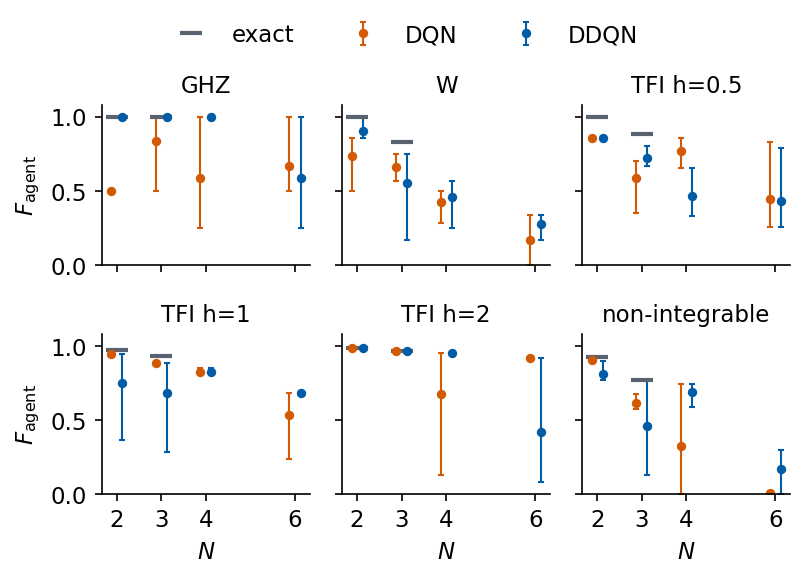

In [22]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.9), sharex=True, sharey=True)
    for ax, name in zip(axs.ravel(), TARGET_NAMES):
        for k, algo in enumerate(ALGOS):
            Fm = np.array([RES[N][(name, algo)]["F"] for N in N_LIST])
            x = np.array(N_LIST) + (k - 0.5) * 0.25
            ax.errorbar(x, Fm.mean(1), yerr=[Fm.mean(1) - Fm.min(1), Fm.max(1) - Fm.mean(1)], fmt="o", ms=3.5,
                        capsize=1.5, lw=1.0, color=ALGO_STYLE[algo]["color"], label=algo)
        ax.plot([2, 3], [BRUTE[N]["best"][-1, TARGET_NAMES.index(name)] for N in (2, 3)], "_", ms=11, mew=2,
                color=UJGray, label="exact")
        ax.set_title(name); ax.set_xticks(N_LIST); ax.set_ylim(0, 1.08)
    for ax in axs[1]: ax.set_xlabel("$N$")
    for ax in axs[:, 0]: ax.set_ylabel(r"$F_{\rm agent}$")
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.92)); save(fig, "fig_lab052_summary"); plt.show()

The fidelity reached by the agents falls with $N$ for most families. For the transverse-field ground state at $h=2$ the agents that find the Hadamard circuit keep $F$ above $0.9$ up to $N=6$, while three seeds stop earlier at a lower fidelity. The fidelity falls fastest for the W state and the non-integrable ground state. The exact references at $N=2,3$ show that part of the gap comes from the discrete gate set and part from the training, which in these runs does not find the best circuit.

### Difficulty and entanglement

We relate the difficulty of a target to its half-chain entanglement entropy. Each point is one target at one chain length, with the final fidelity of the better algorithm averaged over the seeds, and the colour gives $N$.

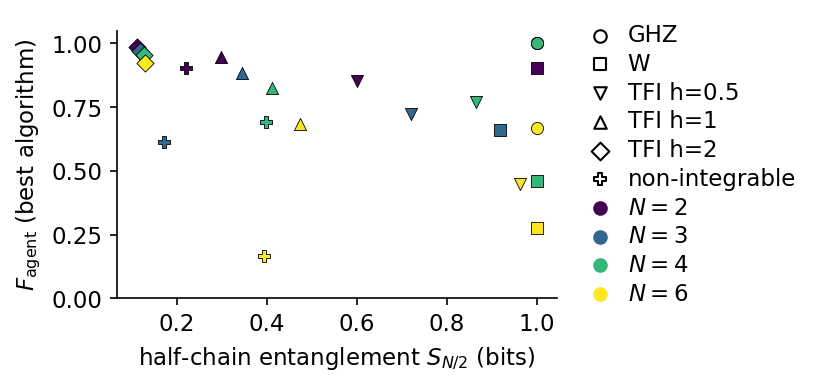

Pearson correlation of S_N/2 and F_agent over all 24 targets: -0.25


In [23]:
pts = []
for N in N_LIST:
    for name in TARGET_NAMES:
        Fb = max(RES[N][(name, a)]["F"].mean() for a in ALGOS)
        pts.append((N, name, S_HALF[N][name], Fb))
cmap = plt.get_cmap("viridis")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.6))
    for N, name, s, Fb in pts:
        st = FAM_STYLE[name]
        ax.scatter(s, Fb, marker=st["marker"], s=34, color=cmap((N_LIST.index(N)) / (len(N_LIST) - 1)),
                   edgecolor="k", lw=0.4, zorder=3)
    for name in TARGET_NAMES:
        ax.scatter([], [], marker=FAM_STYLE[name]["marker"], color="w", edgecolor="k", label=name)
    for N in N_LIST:
        ax.scatter([], [], marker="o", color=cmap(N_LIST.index(N) / (len(N_LIST) - 1)), label=f"$N={N}$")
    ax.set_xlabel(r"half-chain entanglement $S_{N/2}$ (bits)"); ax.set_ylabel(r"$F_{\rm agent}$ (best algorithm)")
    ax.set_ylim(0, 1.05)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), ncol=1, fontsize=11, handletextpad=0.2, labelspacing=0.25)
    fig.tight_layout(); save(fig, "fig_lab052_entanglement_difficulty"); plt.show()
r = np.corrcoef([p[2] for p in pts], [p[3] for p in pts])[0, 1]
print(f"Pearson correlation of S_N/2 and F_agent over all {len(pts)} targets: {r:.2f}")
NUMBERS["CorrEntFid"] = f"{r:.2f}"

The printed correlation coefficient between $S_{N/2}$ and $F_{\rm agent}$ is weak and negative. Entanglement alone does not set the difficulty. The GHZ state carries one bit at every $N$ and is reached by some agents up to $N=6$, while the non-integrable ground state carries less entanglement and is reached with low fidelity. The results above point to the circuit length a target needs, the precision of the rotations it needs and the shape of the fidelity along the circuit as the stronger influences on this agent.

### Gate count against the optimum

For $N\le3$ the exhaustive search gives the best fidelity $F^*(n_{\max})$ and the smallest number of gates $n_{\rm opt}$ with which it is reached, and for the GHZ state at every $N$ the reference is $F=1$ with $n_{\rm opt}=N$. A run is at the optimum when $F_{\rm agent}$ is within $0.005$ of the reference fidelity, and for these runs we compare $n_{\rm agent}$ with $n_{\rm opt}$.

In [24]:
rows = []
for N in N_LIST:
    for name in TARGET_NAMES:
        for algo in ALGOS:
            R_ = RES[N][(name, algo)]
            if N in BRUTE:                    # reference: the exhaustive search
                n_opt, F_ref, ok = BRUTE[N]["n_opt"][name], BRUTE[N]["best"][-1, TARGET_NAMES.index(name)], R_["at_optimum"]
            elif name == "GHZ":               # reference: the GHZ circuit of N gates
                n_opt, F_ref, ok = N, 1.0, R_["success"]
            else:
                continue
            rows.append((N, name, algo, n_opt, F_ref, int(ok.sum()), R_["n"][ok].tolist()))
print(f"{'N':>2} {'target':15s} {'algo':5s} {'F_ref':>6} {'n_opt':>5}  seeds at the optimum, their n_agent")
for N, name, algo, n_opt, F_ref, k, ns in rows:
    print(f"{N:2d} {name:15s} {algo:5s} {F_ref:6.3f} {n_opt:5d}  {k} of {len(SEEDS)}   {ns}")
with_opt = [(n_opt, n) for N, name, algo, n_opt, F_ref, k, ns in rows for n in ns]
frac_opt = np.mean([n == n_opt for n_opt, n in with_opt]) if with_opt else float("nan")
for algo in ALGOS:
    k = sum(r[5] for r in rows if r[2] == algo); m = sum(len(SEEDS) for r in rows if r[2] == algo)
    print(f"{algo}: {k} of {m} runs with a known reference reach the optimal fidelity")
    NUMBERS[f"AtOpt{algo.replace('DDQN', 'Double').replace('DQN', 'Plain')}"] = k
NUMBERS["NRefRuns"] = sum(len(SEEDS) for r in rows if r[2] == "DQN")
print(f"runs at the optimal fidelity: {len(with_opt)}, of these with the optimal gate count: {frac_opt:.2f}")

 N target          algo   F_ref n_opt  seeds at the optimum, their n_agent
 2 GHZ             DQN    1.000     2  0 of 3   []
 2 GHZ             DDQN   1.000     2  3 of 3   [2, 2, 2]
 2 W               DQN    1.000     5  0 of 3   []
 2 W               DDQN   1.000     5  1 of 3   [7]
 2 TFI h=0.5       DQN    1.000     6  0 of 3   []
 2 TFI h=0.5       DDQN   1.000     6  0 of 3   []
 2 TFI h=1         DQN    0.974     6  0 of 3   []
 2 TFI h=1         DDQN   0.974     6  0 of 3   []
 2 TFI h=2         DQN    0.985     2  3 of 3   [2, 2, 2]
 2 TFI h=2         DDQN   0.985     2  3 of 3   [2, 2, 2]
 2 non-integrable  DQN    0.925     8  0 of 3   []
 2 non-integrable  DDQN   0.925     8  0 of 3   []
 3 GHZ             DQN    1.000     3  2 of 3   [3, 3]
 3 GHZ             DDQN   1.000     3  3 of 3   [3, 3, 3]
 3 W               DQN    0.829    10  0 of 3   []
 3 W               DDQN   0.829    10  0 of 3   []
 3 TFI h=0.5       DQN    0.886     7  0 of 3   []
 3 TFI h=0.5       DDQN  

Of the runs that reach the optimal fidelity all but one also use the optimal number of gates. The exception is one DDQN agent for the two-qubit W state, which needs 7 gates where 5 suffice. The cost $\zeta$ per gate and the discount factor $\gamma$ both make a shorter circuit of equal fidelity more valuable, and the reward-design study below shows that for the GHZ state the discount alone already leads to the shortest circuit. DDQN reaches the optimal fidelity in 18 of the 42 runs with a known reference and DQN in 10.

### Learned circuits

The drawing shows the greedy circuits of seed 0, cut at their best fidelity, for four targets. When DQN and DDQN reach different fidelities, the circuit of the better algorithm is drawn, and when they tie, the shorter circuit, with DQN listed for equal circuits.

GHZ, N=4: DDQN ['H3', 'CX32', 'CX21', 'CX10']  F = 1.0000
TFI h=1, N=3: DQN ['H2', 'H1', 'H0']  F = 0.8818
TFI h=2, N=4: DQN ['H0', 'H1', 'H3', 'H2']  F = 0.9527
non-integrable, N=3: DQN ['H2', 'S2', 'H0', 'S0', 'T2', 'S0', 'T0', 'H2', 'H0', 'S0']  F = 0.5735


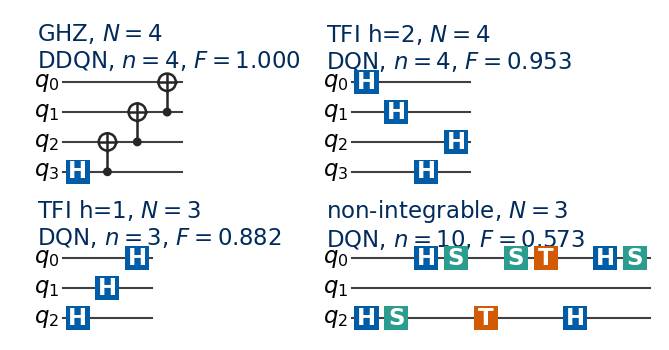

In [25]:
CIRC_SHOW = [[(4, "GHZ"), (3, "TFI h=1")], [(4, "TFI h=2"), (3, "non-integrable")]]   # two columns
def best_seed0_circuit(N, name):
    # seed-0 greedy circuits of both algorithms, cut at their best fidelity; the better one (ties: shorter)
    cand = []
    for algo in ALGOS:
        i = RUNS.index((name, algo, 0))
        F, n = circuit_summary(LOGS[N]["fids"][i, -1])
        cand.append((F, -n, algo, [make_env(N)["gate_names"][a] for a in LOGS[N]["acts"][i, -1][:n]]))
    F, mn, algo, gates = max(cand)
    return F, algo, gates

D_C = 0.62                                                      # spacing of gates and wires
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 3.3))
    x_col, y_min = [0.0, 6.0], 0.0
    for xc, column in zip(x_col, CIRC_SHOW):
        y = 0.0
        for N, name in column:
            F, algo, gates = best_seed0_circuit(N, name)
            ax.text(xc - 0.3, y, f"{name}, $N={N}$\n{algo}, $n={len(gates)}$, $F={F:.3f}$",
                    ha="left", va="top", fontsize=11, color=UJNavy, linespacing=1.15)
            y -= 1.25 + (N - 1) * D_C
            draw_circuit(ax, gates, N, x0=xc + 0.55, dx=D_C, y0=y, dy=D_C, pad=0.3, box_size=0.5)
            y -= 0.55
            print(f"{name}, N={N}: {algo} {gates}  F = {F:.4f}")
        y_min = min(y_min, y)
    ax.set_xlim(-0.75, x_col[1] + 0.55 + D_C * (N_MAX[3] - 1) + 0.4); ax.set_ylim(y_min + 0.2, 0.15)
    ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab052_circuits"); plt.show()

The GHZ circuit for four qubits starts with $\hat H$ on qubit 3 and runs the CNOT cascade from the other end of the chain, a circuit of optimal length that differs from the textbook cascade from qubit 0. The transverse-field circuits apply $\hat H$ to every qubit and prepare $|+\dots+\rangle$, the ground state at infinite field. The circuit for the non-integrable ground state of three qubits uses only single-qubit gates, so it prepares a product state, and it reaches $F\approx0.57$ with ten gates, below the exact optimum $0.769$.

### Reward design

The same compilation task can be posed with four rewards, the fidelity gain or the final fidelity, each with the gate cost $\zeta=0.01$ or without it. We train DDQN agents with all four on two three-qubit targets, the GHZ state, which can be reached exactly, and the transverse-field ground state at $h=1$, which cannot be reached within $n_{\max}$ gates. For every agent we record the fidelity at the end of its greedy episode, $F_{\rm end}$, either at the first gate with $F>0.99$ or after $n_{\max}$ gates, and the number of gates $n_{\rm end}$ it applied.

In [26]:
REWARDS = [("gain - cost", ZETA, False), ("gain", 0.0, False), ("final - cost", ZETA, True), ("final", 0.0, True)]
RW_TARGETS, N_RW = ["GHZ", "TFI h=1"], 3
RW_RUNS = [(t, rw, seed) for t in RW_TARGETS for rw in range(len(REWARDS)) for seed in SEEDS]
train_rw = jax.pmap(jax.vmap(make_trainer(make_env(N_RW), CFG)))
n_dev_rw = max(d for d in range(1, len(jax.devices()) + 1) if len(RW_RUNS) % d == 0)
shard_rw = lambda x: x.reshape((n_dev_rw, -1) + x.shape[1:])
t0 = time.time()
logs_rw = jax.block_until_ready(train_rw(
    shard_rw(jnp.stack([jax.random.PRNGKey(7000 + 10 * rw + s) for _, rw, s in RW_RUNS])),
    shard_rw(jnp.stack([TARGETS[N_RW][t] for t, _, _ in RW_RUNS])),
    shard_rw(jnp.ones(len(RW_RUNS), bool)),
    shard_rw(jnp.array([REWARDS[rw][1] for _, rw, _ in RW_RUNS])),
    shard_rw(jnp.array([REWARDS[rw][2] for _, rw, _ in RW_RUNS])),
    shard_rw(jnp.zeros(len(RW_RUNS), jnp.int32))))
T_TRAIN["rewards"] = time.time() - t0
fids_rw = np.asarray(logs_rw[0]).reshape((len(RW_RUNS),) + logs_rw[0].shape[2:])[:, -1]   # last recorded circuits

def episode_end(fids_row):
    # fidelity and gate count where the greedy episode ends: first gate with F > 0.99, or after n_max gates
    hit = np.nonzero(fids_row > F_SUCCESS)[0]
    k = int(hit[0]) if len(hit) else len(fids_row) - 1
    return float(fids_row[k]), k + 1

RW = {}
print(f"{'target':8s} {'reward':13s} F_end per seed           n_end per seed   ({T_TRAIN['rewards']:.0f} s)")
for t in RW_TARGETS:
    for rw, (name, zeta, final) in enumerate(REWARDS):
        res = [episode_end(fids_rw[i]) for i, r in enumerate(RW_RUNS) if r[0] == t and r[1] == rw]
        RW[(t, name)] = res
        print(f"{t:8s} {name:13s} {str(np.round([f for f, _ in res], 3)):24s} {[n for _, n in res]}")

target   reward        F_end per seed           n_end per seed   (70 s)
GHZ      gain - cost   [1. 1. 1.]               [3, 3, 3]
GHZ      gain          [1. 1. 1.]               [3, 3, 3]
GHZ      final - cost  [0.5  0.25 0.75]         [10, 10, 10]
GHZ      final         [0.427 0.375 0.427]      [10, 10, 10]
TFI h=1  gain - cost   [0.882 0.882 0.882]      [10, 10, 10]
TFI h=1  gain          [0.882 0.753 0.882]      [10, 10, 10]
TFI h=1  final - cost  [0.753 0.661 0.582]      [10, 10, 10]
TFI h=1  final         [0.366 0.661 0.605]      [10, 10, 10]


For the GHZ state both rewards built on the fidelity gain lead every agent to the three-gate circuit. With the final-fidelity reward no agent reaches the target, and the episodes end after $n_{\max}$ gates with $F$ between $0.25$ and $0.75$. The final reward arrives only at the end of an episode, usually after ten gates, and an exploring agent rarely meets the GHZ state on the way, so the reward carries little information about which early gate led to a good end. This comparison has a confound. The final-fidelity reward is paid at the time limit, but the step counter is absent from the input, so the same state and gate receive reward zero or $F$ depending on a hidden time. The time-limit transition is also bootstrapped. The failure can therefore come from sparse credit assignment, from this non-Markov specification, or from both, and these runs do not separate the two. For the transverse-field target five of the six agents trained with the gain rewards reach the Hadamard circuit value $0.882$, and the final rewards give lower values between $0.37$ and $0.75$. The gate cost makes no measurable difference in these runs, since the GHZ circuits are already of optimal length and the transverse-field episodes always run to $n_{\max}$. In these runs the fidelity gain gives the agent a signal for every gate. The final-fidelity runs would need time in the input and a terminal time limit before they measure the effect of reward sparsity alone.

### DQN against DDQN

The last table counts, for every chain length, the successful runs of each algorithm over all targets and seeds and gives the mean final fidelity.

In [27]:
CMP = {}
for N in N_LIST:
    CMP[N] = {}
    for algo in ALGOS:
        F = np.concatenate([RES[N][(n, algo)]["F"] for n in TARGET_NAMES])
        CMP[N][algo] = dict(success=int((F > F_SUCCESS).sum()), runs=len(F), F_mean=float(F.mean()))
    print(f"N = {N}:  " + "   ".join(f"{a} {CMP[N][a]['success']}/{CMP[N][a]['runs']} successful, mean F = {CMP[N][a]['F_mean']:.3f}" for a in ALGOS))
tot = {a: sum(CMP[N][a]["success"] for N in N_LIST) for a in ALGOS}
print("successful runs over all N:", tot)

N = 2:  DQN 0/18 successful, mean F = 0.821   DDQN 4/18 successful, mean F = 0.884
N = 3:  DQN 2/18 successful, mean F = 0.757   DDQN 3/18 successful, mean F = 0.731
N = 4:  DQN 1/18 successful, mean F = 0.601   DDQN 3/18 successful, mean F = 0.732
N = 6:  DQN 1/18 successful, mean F = 0.457   DDQN 1/18 successful, mean F = 0.427
successful runs over all N: {'DQN': 4, 'DDQN': 11}


DDQN reaches the optimal fidelity in 18 of the 42 runs with an exact reference and DQN in 10, and over the 72 runs of each algorithm DDQN reaches $F>0.99$ in 11 and DQN in 4. The mean final fidelity is higher for DDQN at $N=2$ and $4$ and slightly lower at $N=3$ and $6$. With the exact reward the advantage of DDQN is therefore visible in how often the target is reached, while the mean fidelity varies between the chain lengths. Three seeds per target leave this comparison with a large statistical uncertainty. The next section adds the noise of a real measurement, which is the situation in which the bias of the maximum is expected to matter most.

### Shot noise and overestimation

On a quantum device the fidelity has to be measured. One measurement shot applies the inverse of the target preparation, $\hat U_{\rm target}^\dagger$ with $\hat U_{\rm target}|0\dots0\rangle=|\psi_{\rm target}\rangle$, and measures all qubits. It returns the outcome $0\dots0$ with probability $F$, and we count this outcome as 1 and every other outcome as 0. This measurement needs a circuit for the target, which exists for the GHZ state studied below, and for other targets a device would use other fidelity estimators. We use it as a model of measurement noise with binomial statistics. With $n_s$ shots the number $k$ of ones follows the binomial distribution, and the estimate
$$\tilde F=\frac{k}{n_s},\qquad \mathbb E\tilde F=F,\qquad \sigma_{\tilde F}=\sqrt{\frac{F(1-F)}{n_s}}$$
is unbiased with a standard deviation that falls as $1/\sqrt{n_s}$. We let the environment compute the reward from estimated fidelities, $r_{t+1}=\tilde F_{t+1}-\tilde F_t-\zeta$, with fresh shots for every estimate. The end of the episode is still decided by the exact fidelity, so only the reward is noisy. The noise has zero mean, the expected reward and the best circuits are unchanged, and only the learned action values become noisy. This is the situation of the toy model above, in which the maximum in the DQN target is biased upwards. The cell below checks the size of the noise for $F=1/2$, for one fidelity estimate and for the reward, which is the difference of two independent estimates.

In [28]:
rng_shots = np.random.default_rng(1)
for n_s in (10, 3):
    F_hat = rng_shots.binomial(n_s, 0.5, size=100_000) / n_s
    r_hat = (rng_shots.binomial(n_s, 0.5, size=100_000) - rng_shots.binomial(n_s, 0.5, size=100_000)) / n_s
    print(f"n_s = {n_s:2d}:  sigma = sqrt(F(1-F)/n_s) = {np.sqrt(0.25 / n_s):.3f}   sampled mean {F_hat.mean():.3f}, sampled std {F_hat.std():.3f}"
          f"   std of F_hat_(t+1) - F_hat_t = {r_hat.std():.3f}")

n_s = 10:  sigma = sqrt(F(1-F)/n_s) = 0.158   sampled mean 0.500, sampled std 0.158   std of F_hat_(t+1) - F_hat_t = 0.224
n_s =  3:  sigma = sqrt(F(1-F)/n_s) = 0.289   sampled mean 0.501, sampled std 0.289   std of F_hat_(t+1) - F_hat_t = 0.408


With ten shots the standard deviation of one estimate at $F=1/2$ is $0.16$, comparable to the fidelity steps of $1/4$ along the GHZ circuit, and with three shots it is $0.29$. The reward contains two independent estimates, so its standard deviation is larger by $\sqrt2$, as the last printed column shows.

To measure an overestimation we need the true value of the initial state. For the GHZ state of three qubits it follows exactly from backward induction over all distinct states reachable within $n_{\max}=10$ gates. With $V_{n_{\max}}(s)=0$ and
$$V_t(s)=\max_a\Big[F(s')-F(s)-\zeta+\gamma\,(1-d(s'))\,V_{t+1}(s')\Big],\qquad s'=\hat U_a s ,$$
where $d(s')=1$ when $F(s')>0.99$, the number $G_*=V_0(|000\rangle)$ is the largest expected discounted return of any circuit with at most $n_{\max}$ gates. A predicted value $\max_aQ_\theta(s_0,a)$ above $G_*$ is an overestimation.

In [29]:
def reachable_states(N, n_max):
    # all distinct states within n_max gates and the successor table nxt[i, a] (exact fidelities, no sampling)
    gates = gate_set(N)
    all_next = jax.jit(jax.vmap(lambda p: jnp.stack([apply_gate(p, U, q) for _, U, q in gates])))
    def key(v):
        k = np.argmax(np.abs(v) > 1e-4); c = v * (abs(v[k]) / v[k])
        return (np.round(np.r_[c.real, c.imag], 4).astype(np.float32) + 0.0).tobytes()
    states = [np.asarray(zero_state(N)).reshape(-1)]; index = {key(states[0]): 0}; front = [0]
    succ = {}                                                  # succ[i] = indices of the successors of state i
    for depth in range(n_max):
        nxt = np.asarray(all_next(jnp.asarray(np.stack([states[i] for i in front]).reshape((-1,) + (2,) * N))))
        new_front = []
        for i, block in zip(front, nxt.reshape(len(front), len(gates), -1)):
            succ[i] = []
            for v in block:
                k = key(v)
                if k not in index:
                    index[k] = len(states); states.append(v); new_front.append(index[k])
                succ[i].append(index[k])
        front = new_front
    nxt = np.array([succ.get(i, [i] * len(gates)) for i in range(len(states))])   # states at depth n_max: never expanded
    return np.array(states), nxt

def optimal_return(N, target, n_max, cost=ZETA, graph=None):
    # G* = V_0(|0...0>) by backward induction over all distinct states within n_max gates, and a circuit that attains it
    # cost: one number for every gate, or an array with one cost per gate of the gate set
    states, nxt = reachable_states(N, n_max) if graph is None else graph
    F = np.abs(states @ np.asarray(target).reshape(-1).conj()) ** 2
    cost = np.broadcast_to(np.asarray(cost, dtype=float), (nxt.shape[1],))
    V = [np.zeros(len(states))]                                # V_{n_max} = 0, then V_{n_max-1}, ..., V_0
    for t in range(n_max):
        Q = F[nxt] - F[:, None] - cost[None, :] + GAMMA * (F[nxt] <= F_SUCCESS) * V[-1][nxt]
        V.append(Q.max(1))
    i, circuit = 0, []                                         # follow the best gates from |0...0>
    for t in range(n_max):
        Q = F[nxt[i]] - F[i] - cost + GAMMA * (F[nxt[i]] <= F_SUCCESS) * V[n_max - 1 - t][nxt[i]]
        a = int(np.argmax(Q)); circuit.append(a); i = nxt[i, a]
        if F[i] > F_SUCCESS:
            break
    return float(V[-1][0]), len(states), circuit

G_STAR, n_states, _ = optimal_return(3, TARGETS[3]["GHZ"], N_MAX[3])
G_circuit = -0.25 - ZETA + GAMMA * (0.0 - ZETA) + GAMMA ** 2 * (0.75 - ZETA)     # the circuit H0, CX01, CX12
print(f"G* = {G_STAR:.4f} over {n_states} states;  return of H0, CX01, CX12 = {G_circuit:.4f}")

G* = 0.3983 over 68795 states;  return of H0, CX01, CX12 = 0.3983


The exact optimum $G_*$ equals the discounted return of the three-gate GHZ circuit, $-0.26-0.95\cdot0.01+0.95^2\cdot0.74$, so no circuit of up to $n_{\max}$ gates does better. We now train DQN and DDQN agents on this target with the exact reward and with $n_s=10$ and $n_s=3$ shots per fidelity estimate, five seeds each, with the same settings as before.

In [30]:
SHOTS, SEEDS_SN, N_SN = [0, 10, 3], [0, 1, 2, 3, 4], 3
SN_RUNS = [(n_s, algo, seed) for n_s in SHOTS for algo in ALGOS for seed in SEEDS_SN]
train_sn = jax.pmap(jax.vmap(make_trainer(make_env(N_SN), CFG)))
n_dev_sn = max(d for d in range(1, len(jax.devices()) + 1) if len(SN_RUNS) % d == 0)
shard_sn = lambda x: x.reshape((n_dev_sn, -1) + x.shape[1:])
t0 = time.time()
logs_sn = jax.block_until_ready(train_sn(
    shard_sn(jnp.stack([jax.random.PRNGKey(500 + s) for _, _, s in SN_RUNS])),
    shard_sn(jnp.stack([TARGETS[N_SN]["GHZ"]] * len(SN_RUNS))),
    shard_sn(jnp.array([a == "DDQN" for _, a, _ in SN_RUNS])),
    shard_sn(jnp.full(len(SN_RUNS), ZETA)), shard_sn(jnp.zeros(len(SN_RUNS), bool)),
    shard_sn(jnp.array([n_s for n_s, _, _ in SN_RUNS], jnp.int32))))
T_TRAIN["shots"] = time.time() - t0
fids_sn, _, q0_sn, _ = (np.asarray(x).reshape((len(SN_RUNS),) + x.shape[2:]) for x in logs_sn)
SN = {}
for n_s in SHOTS:
    for algo in ALGOS:
        idx = [i for i, r in enumerate(SN_RUNS) if r[0] == n_s and r[1] == algo]
        succ = [bool(fids_sn[i, -1].max() > F_SUCCESS) for i in idx]
        SN[(n_s, algo)] = dict(success=int(sum(succ)), q0=q0_sn[idx], F=fids_sn[idx, -1].max(1))
        print(f"n_s = {n_s if n_s else 'exact':>5}  {algo:4s}: reaches the GHZ state in {sum(succ)} of {len(idx)} seeds,"
              f"  max_a Q(s_0,a) after training = {np.round(q0_sn[idx, -1], 2)}   (G* = {G_STAR:.3f})")
print(f"training time {T_TRAIN['shots']:.0f} s")

n_s = exact  DQN : reaches the GHZ state in 4 of 5 seeds,  max_a Q(s_0,a) after training = [0.35 0.4  0.4  0.4  0.37]   (G* = 0.398)
n_s = exact  DDQN: reaches the GHZ state in 5 of 5 seeds,  max_a Q(s_0,a) after training = [0.4  0.4  0.4  0.4  0.41]   (G* = 0.398)
n_s =    10  DQN : reaches the GHZ state in 0 of 5 seeds,  max_a Q(s_0,a) after training = [0.91 0.94 0.91 0.96 0.93]   (G* = 0.398)
n_s =    10  DDQN: reaches the GHZ state in 3 of 5 seeds,  max_a Q(s_0,a) after training = [0.41 0.38 0.39 0.42 0.43]   (G* = 0.398)
n_s =     3  DQN : reaches the GHZ state in 0 of 5 seeds,  max_a Q(s_0,a) after training = [1.46 1.07 1.34 1.81 1.69]   (G* = 0.398)
n_s =     3  DDQN: reaches the GHZ state in 0 of 5 seeds,  max_a Q(s_0,a) after training = [0.4  0.4  0.41 0.3  0.31]   (G* = 0.398)
training time 81 s


The figure shows the predicted value $\max_aQ_\theta(s_0,a)$ of the initial state during training, the mean over the five seeds with the band between the lowest and the highest seed, for the exact reward and for the two shot numbers. The dotted line is the exact optimum $G_*$, and the text in each panel gives the number of seeds whose final greedy circuit reaches $F>0.99$.

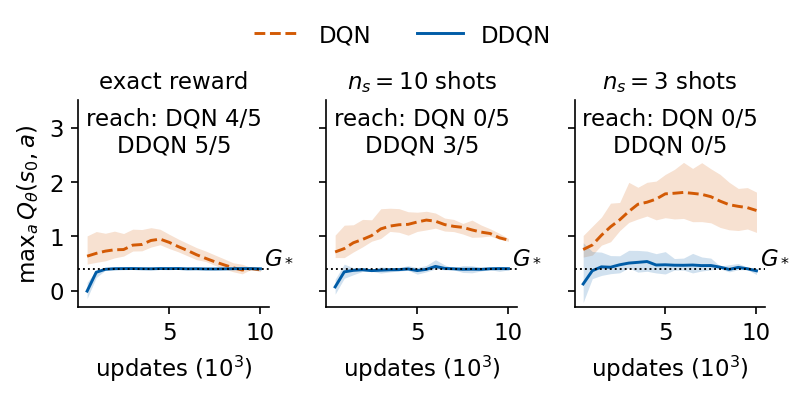

In [31]:
upd = (np.arange(CFG["n_updates"] // CFG["eval_every"]) + 1) * CFG["eval_every"] / 1e3
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.7), sharey=True)
    for ax, n_s in zip(axs, SHOTS):
        for algo in ALGOS:
            q = SN[(n_s, algo)]["q0"]
            ax.fill_between(upd, q.min(0), q.max(0), color=ALGO_STYLE[algo]["color"], alpha=0.18, lw=0)
            ax.plot(upd, q.mean(0), label=algo, **ALGO_STYLE[algo])
        ax.axhline(G_STAR, color="k", lw=0.9, ls=":")
        ax.set_title("exact reward" if n_s == 0 else f"$n_s={n_s}$ shots")
        ax.set_xlabel(r"updates ($10^3$)")
        reach = "  ".join(f"{a} {SN[(n_s, a)]['success']}/{len(SEEDS_SN)}" for a in ALGOS)
        ax.text(0.5, 0.97, "reach: " + reach.replace("  ", "\n"), transform=ax.transAxes, ha="center", va="top", fontsize=11)
        ax.text(10.2, G_STAR + 0.04, "$G_*$", va="bottom", ha="left", fontsize=11)     # label just above the dotted line
    axs[0].set_ylabel(r"$\mathrm{max}_a\,Q_\theta(s_0,a)$"); axs[0].set_ylim(-0.3, 3.5)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.9)); save(fig, "fig_lab052_shot_noise"); plt.show()
NUMBERS["GStar"] = f"{G_STAR:.3f}"
for n_s, tag in ((0, "Exact"), (10, "TenShots"), (3, "ThreeShots")):
    for algo in ALGOS:
        a = algo.replace("DDQN", "Double").replace("DQN", "Plain")
        NUMBERS[f"Reach{a}{tag}"] = SN[(n_s, algo)]["success"]
        NUMBERS[f"Qzero{a}{tag}"] = f"{SN[(n_s, algo)]['q0'][:, -1].mean():.2f}"
NUMBERS["NSeedsShots"] = len(SEEDS_SN)

With the exact reward both algorithms learn the value of the initial state, and their predictions after training lie close to $G_*=0.398$, with four of five DQN seeds and all five DDQN seeds reaching the target. The figure shows the full training history of these predictions for every setting. With ten shots the DQN prediction rises to about $0.93$, more than twice the exact optimum $G_*$, and no DQN agent reaches the GHZ state. The DDQN prediction stays at $G_*$ within a few hundredths, and three of the five DDQN agents reach the target. With three shots the mean DQN prediction exceeds $G_*$ by more than a factor of three, the DDQN predictions stay within $0.1$ of $G_*$, and neither algorithm reaches the target in the training time.

The measurement noise has zero mean and leaves the best circuit unchanged. The DQN target takes the maximum over the noisy action values of the next state, and this maximum is biased upwards, as in the toy model with independent errors. The bias is passed back to earlier states through the Bellman equation, and the predicted value of the initial state grows far above $G_*$. An agent that ranks gates by these inflated values can prefer gates whose values are overestimated most, and the DQN agents with noisy rewards do not find the GHZ circuit. DDQN evaluates the action chosen by the online network with the target network, its predictions stay calibrated, and with ten shots it still learns the circuit. With three shots the noise of a single fidelity estimate, $\sigma\approx0.29$, is larger than most fidelity steps, and within $10^4$ updates neither algorithm learns the circuit.

<hr/>
## 9. Fewer gates and fewer CNOTs

The DQN and DDQN agents of the previous sections are now compared with a second family of methods, policy gradient, on the GHZ and W states for the same chain lengths. Before the comparison we sharpen the part of the reward that asks for short circuits, and we apply the same reward to both families.

Three parts of the task already favour short circuits. Every gate costs $\zeta$, the discount factor $\gamma<1$ makes a fidelity gain worth more when it comes earlier, and an episode ends as soon as $F>0.99$, so a circuit that reaches the target early stops paying the gate cost. The gate cost so far is the same for every gate. When a CNOT is more error-prone than a single-qubit gate, a circuit with fewer CNOTs can be the better circuit even when it is longer. We therefore give every gate $a$ its own cost $c(a)$,
$$r_{t+1}=F_{t+1}-F_t-c(a_t),\qquad c(a)=\begin{cases}\zeta=0.01 & \text{for } \hat H,\ \hat S,\ \hat T,\\ \zeta_{\rm CX}=0.03 & \text{for a CNOT},\end{cases}$$
so that a CNOT costs as much as three single-qubit gates. The undiscounted return of an episode with $n_1$ single-qubit gates and $n_{\rm CX}$ CNOTs becomes $F_n-F_0-\zeta n_1-\zeta_{\rm CX}n_{\rm CX}$.

The reference for the learned circuits comes from three sources. The GHZ circuit introduced with the targets has $N$ gates and $N-1$ CNOTs, the smallest possible numbers of both, so it is the best circuit for any positive costs. For $N=2$ and $3$ the backward induction of the shot-noise study, run with the cost $c(a)$, gives the largest discounted return $G_*$ and a circuit that attains it. For every target we also count the gate sequences of the shortest length that reach $F>0.99$, which tells us how many equivalent shortest circuits an agent can find.

In [32]:
ZETA_CX = 0.03                                             # cost of one CNOT, single-qubit gates keep ZETA = 0.01

def cost_vector(env, zeta=ZETA, zeta_cx=ZETA_CX):
    # one cost per gate of the gate set: zeta for H, S, T and zeta_cx for every CNOT
    return jnp.array([zeta_cx if g.startswith("CX") else zeta for g in env["gate_names"]])

def n_cnot(gates):
    return sum(g.startswith("CX") for g in gates)

def run_circuit(N, gates):
    # the state prepared from |0...0> by a list of gate names
    lookup = {g: (U, q) for g, U, q in gate_set(N)}
    psi = zero_state(N)
    for g in gates:
        psi = apply_gate(psi, *lookup[g])
    return psi

def count_sequences(N, target, L):
    # number of gate sequences of exactly L gates that reach F > 0.99 at the last gate and not before, by CNOT count
    gates = gate_set(N); is_cx = [g.startswith("CX") for g, _, _ in gates]
    all_next = jax.jit(jax.vmap(lambda p: jnp.stack([apply_gate(p, U, q) for _, U, q in gates])))
    def key(v):
        k = np.argmax(np.abs(v) > 1e-4); c = v * (abs(v[k]) / v[k])
        return (np.round(np.r_[c.real, c.imag], 4).astype(np.float32) + 0.0).tobytes()
    tg = np.asarray(target).reshape(-1)
    v0 = np.asarray(zero_state(N)).reshape(-1)
    layer = {key(v0): (v0, {0: 1})}                       # state -> (vector, {CNOT count: number of sequences})
    for d in range(L):
        keys = list(layer)
        nxt = np.asarray(all_next(jnp.asarray(np.stack([layer[k][0] for k in keys]).reshape((-1,) + (2,) * N))))
        new = {}
        for i, k in enumerate(keys):
            for a, v in enumerate(nxt[i].reshape(len(gates), -1)):
                if abs(np.vdot(tg, v)) ** 2 > F_SUCCESS and d < L - 1:
                    continue                               # this episode would have ended at an earlier gate
                vec, counts = new.setdefault(key(v), (v, {}))
                for c, m in layer[k][1].items():
                    counts[c + is_cx[a]] = counts.get(c + is_cx[a], 0) + m
        layer = new
    hits = {}
    for v, counts in layer.values():
        if abs(np.vdot(tg, v)) ** 2 > F_SUCCESS:
            for c, m in counts.items():
                hits[int(c)] = hits.get(int(c), 0) + m
    return dict(sorted(hits.items()))

# exact best circuits for N = 2, 3 with the uniform cost and with the CNOT cost
GRAPH = {N: reachable_states(N, N_MAX[N]) for N in (2, 3)}
OPT = {}
for N in (2, 3):
    env = make_env(N)
    for name in ("GHZ", "W"):
        for label, cost in (("uniform", ZETA), ("CNOT", np.asarray(cost_vector(env)))):
            G, _, circ = optimal_return(N, TARGETS[N][name], N_MAX[N], cost, GRAPH[N])
            gates = [env["gate_names"][a] for a in circ]
            F = float(fidelity_pure(TARGETS[N][name], run_circuit(N, gates)))
            OPT[(N, name, label)] = dict(G=G, F=F, gates=gates, n=len(gates), n_cx=n_cnot(gates))
            print(f"{name}_{N}  cost {label:7s}  G* = {G:.4f}   F = {F:.3f}   n = {len(gates):2d}   CNOTs = {n_cnot(gates)}   {gates}")

def circuit_return(N, target, gates, cost):
    # discounted return of a fixed circuit; the episode ends at the first gate with F > 0.99
    env = make_env(N); psi, G = env["psi0"], 0.0
    for t, g in enumerate(gates):
        psi, r, done = env["step"](psi, env["gate_names"].index(g), target, False, jnp.asarray(cost))
        G += GAMMA ** t * float(r)
        if bool(done):
            break
    return G

W2_SHORT_RETURN = circuit_return(2, TARGETS[2]["W"], OPT[(2, "W", "uniform")]["gates"], cost_vector(make_env(2)))
print(f"W_2 with the CNOT cost: return of the shortest circuit {W2_SHORT_RETURN:.4f}, best return G* = {OPT[(2, 'W', 'CNOT')]['G']:.4f}")

# the number of equivalent shortest sequences
SHORTEST_COUNT = {}
for N, name, L in ((2, "GHZ", 2), (3, "GHZ", 3), (4, "GHZ", 4), (2, "W", 5), (2, "W", 6)):
    SHORTEST_COUNT[(N, name, L)] = count_sequences(N, TARGETS[N][name], L)
    print(f"{name}_{N}: sequences of {L} gates that reach F > 0.99, by number of CNOTs: {SHORTEST_COUNT[(N, name, L)]}")

# W_4 has no exhaustive search within n_max = 12; the search up to 9 gates gives a lower bound on its best fidelity
t0 = time.time()
_, best4, _ = breadth_first(4, 9, {"W": TARGETS[4]["W"]})
W4_LOWER = float(best4[-1, 0])
print(f"W_4: best fidelity within 9 gates F*(9) = {W4_LOWER:.3f}   ({time.time() - t0:.0f} s)")

GHZ_2  cost uniform  G* = 0.4430   F = 1.000   n =  2   CNOTs = 1   ['H0', 'CX01']
GHZ_2  cost CNOT     G* = 0.4240   F = 1.000   n =  2   CNOTs = 1   ['H0', 'CX01']
W_2  cost uniform  G* = 0.8043   F = 1.000   n =  5   CNOTs = 2   ['H0', 'CX01', 'H0', 'CX01', 'H0']
W_2  cost CNOT     G* = 0.7726   F = 1.000   n =  6   CNOTs = 1   ['H0', 'S0', 'S0', 'H0', 'H1', 'CX10']


GHZ_3  cost uniform  G* = 0.3983   F = 1.000   n =  3   CNOTs = 2   ['H0', 'CX01', 'CX12']


GHZ_3  cost CNOT     G* = 0.3613   F = 1.000   n =  3   CNOTs = 2   ['H0', 'CX01', 'CX12']


W_3  cost uniform  G* = 0.5575   F = 0.829   n = 10   CNOTs = 3   ['H1', 'CX12', 'H1', 'CX12', 'H1', 'H0', 'T0', 'H0', 'CX01', 'S0']


W_3  cost CNOT     G* = 0.5081   F = 0.829   n = 10   CNOTs = 3   ['H1', 'CX12', 'H1', 'CX12', 'H1', 'H0', 'T0', 'H0', 'CX01', 'S0']
W_2 with the CNOT cost: return of the shortest circuit 0.7682, best return G* = 0.7726


GHZ_2: sequences of 2 gates that reach F > 0.99, by number of CNOTs: {1: 2}


GHZ_3: sequences of 3 gates that reach F > 0.99, by number of CNOTs: {2: 4}


GHZ_4: sequences of 4 gates that reach F > 0.99, by number of CNOTs: {3: 8}


W_2: sequences of 5 gates that reach F > 0.99, by number of CNOTs: {2: 8}


W_2: sequences of 6 gates that reach F > 0.99, by number of CNOTs: {1: 58, 2: 48, 3: 32}


W_4: best fidelity within 9 gates F*(9) = 0.562   (3 s)


The printed optima agree with this GHZ circuit for both costs. For the two-qubit W state the CNOT cost changes the best circuit. With the uniform cost the shortest circuit, five gates with two CNOTs, is also the best one. With $\zeta_{\rm CX}=0.03$ the best circuit has six gates and a single CNOT, so the extra cost of a CNOT outweighs one additional single-qubit gate. For the three-qubit W state no circuit within $n_{\max}=10$ gates reaches $F>0.99$, and the best circuit for both costs is the ten-gate circuit with $F=0.829$ and three CNOTs. For four qubits the search up to nine gates gives $F=0.562$ for the W state, a lower bound on the best fidelity within $n_{\max}=12$ gates, since the full search no longer fits in memory.

The counts show that the shortest GHZ circuit is far from unique. There are 2, 4 and 8 shortest sequences for $N=2$, $3$ and $4$, that is $2^{N-1}$. The Hadamard gate can act on any qubit, and the CNOTs then spread the correlation outwards in both directions along the chain, and the two directions can be interleaved. The two-qubit W state has 8 shortest sequences of five gates, and among the six-gate sequences 58 use a single CNOT.

<hr/>
## 10. Policy gradient

Deep Q-learning learns the value of every gate and obtains the policy from these values, by choosing the gate with the largest one. A policy-gradient method learns the policy itself. A neural network returns, for the state $s$, a probability $\pi_\theta(a|s)$ for every gate $a$, and the agent samples the next gate from these probabilities. Training changes the parameters $\theta$ so that circuits with a large return become more probable.

Everything else of the compilation task stays as it is. The input is the vector $s_t=(\mathrm{Re}\,\psi_t,\mathrm{Im}\,\psi_t)$ of the state with the standard global phase, the actions are the same $5N-2$ gates, and the reward with the cost $c(a)$, the discount factor $\gamma=0.95$, the success threshold $F>0.99$ and the time limit $n_{\max}=2N+4$ are those of the DQN agents. The policy network has the shape of the Q-network, two hidden layers of 128 ReLU units and one output $z_a(s)$ per gate, and the softmax function turns the outputs into probabilities,
$$\pi_\theta(a|s)=\frac{e^{z_a(s)}}{\sum_{a'}e^{z_{a'}(s)}} .$$
This is the Boltzmann distribution over the gates with the energies $-z_a(s)$ at unit temperature. The weights of the output layer start at zero, so the initial policy chooses every gate with probability $1/(5N-2)$, as the DQN agent does at the start of its training, when $\epsilon=1$.

### REINFORCE

The agent maximises the expected discounted return from the initial state,
$$J(\theta)=\mathbb E_{\pi_\theta}\big[G_0\big],\qquad G_t=\sum_{k\ge0}\gamma^k r_{t+k+1},$$
where $G_t$ is the discounted return collected after step $t$ and the average runs over the episodes generated by the policy. REINFORCE episodes end at the time limit $n_{\max}$, a finite horizon, while the DQN target bootstraps through that limit without the remaining budget in its input. The two objectives coincide when the optimal circuit reaches the success threshold well before the limit, as for the GHZ targets, where $J$ of the optimal policy equals $\max_aQ^*(s_0,a)$. For targets that the gate set cannot reach within $n_{\max}$ gates the two families optimise different continuation conventions. The policy gradient theorem [R. S. Sutton, D. McAllester, S. Singh, Y. Mansour, Adv. Neural Inf. Process. Syst. **12**, 1057 (2000), <https://proceedings.nips.cc/paper_files/paper/1999/hash/464d828b85b0bed98e80ade0a5c43b0f-Abstract.html>] writes the gradient of $J$ as an average over these episodes,
$$\nabla_\theta J=\mathbb E_{\pi_\theta}\Big[\sum_{t}\gamma^t\,G_t\,\nabla_\theta\ln\pi_\theta(a_t|s_t)\Big].$$
The REINFORCE algorithm [R. J. Williams, Mach. Learn. **8**, 229 (1992), [doi:10.1007/BF00992696](https://doi.org/10.1007/BF00992696)] estimates this average with a batch of $B=32$ episodes sampled from the current policy and takes one step of the Adam optimiser with the estimate $\tilde g$. A gate followed by a large return becomes more probable and a gate followed by a small return less probable. The method needs no value network, no replay memory and no target network. Each batch of episodes is used for one update only, because the average is taken over the episodes of the current policy.

### Baseline

The returns of single episodes scatter strongly, and so does $\tilde g$. Any number $b_t$ that does not depend on the action $a_t$ can be subtracted from $G_t$ without changing the average, since
$$\mathbb E_{a\sim\pi_\theta}\big[\nabla_\theta\ln\pi_\theta(a|s)\big]=\sum_a\nabla_\theta\pi_\theta(a|s)=\nabla_\theta\sum_a\pi_\theta(a|s)=\nabla_\theta1=0 ,$$
and a well-chosen $b_t$ reduces the variance of $\tilde g$. All episodes start in $|0\dots0\rangle$ and the gates act deterministically, so the episodes of one batch can be compared at equal step $t$. As baseline of episode $i$ at step $t$ we take the mean return of the other episodes of the batch that are still running at that step,
$$b_t^{(i)}=\frac{1}{|\mathcal R_t|-1}\sum_{j\in\mathcal R_t,\ j\neq i}G_t^{(j)} ,$$
where $\mathcal R_t$ is the set of running episodes. Leaving out episode $i$ makes $b_t^{(i)}$ independent of the gates of episode $i$, and the estimate stays unbiased. The update then uses the advantage $G_t-b_t$, which is positive for a gate that did better than the other episodes at the same step. A learned value network $V_\phi(s_t)$ would adapt the baseline to the state, at the price of a second network with its own training. For a fixed initial state and a batch of 32 episodes the batch mean needs no extra parameters, and we use it.

### Exploration and the entropy bonus

DQN explores through $\epsilon$, which keeps a fraction of random gates for most of the training. A policy-gradient agent explores only by sampling, and its exploration shrinks as the policy becomes sharper. In this task the policy sharpens too early. Along the GHZ circuit the reward starts with a loss, while an agent that applies only phase gates to $|0\dots0\rangle$ keeps $F=F_0$ and pays only the gate cost. The sampled episodes favour these idle gates, the policy concentrates on them, and the rare successful episodes stop appearing. We therefore add the entropy of the policy to the objective,
$$J_\beta(\theta)=J(\theta)+\beta\,\mathbb E\big[\mathcal S(\pi_\theta(\cdot|s_t))\big],\qquad \mathcal S(\pi)=-\sum_a\pi(a)\ln\pi(a),$$
where $\mathcal S$ is the Gibbs entropy of the gate distribution, largest for the uniform policy. The coefficient $\beta$ falls linearly from $\beta_0=1$ to zero over the first 60% of the training, the shape of the $\epsilon$ schedule of DQN, and the final policy maximises the return alone.

The tuning budget of the two families differs, and we state it. The DQN and DDQN agents keep every setting of the earlier sections. For REINFORCE we tried nine settings on the three-qubit GHZ state, with seeds that do not appear below. They combined two initialisations of the output layer, drawn like that of the Q-network or set to zero, the learning rates $3\times10^{-4}$, $10^{-3}$ and $3\times10^{-3}$, and entropy coefficients of zero, constant values up to $0.1$, and the decreasing schedule with $\beta_0=0.1$, $0.3$ and $1$. Among these trial runs, which are not part of this notebook, only the decreasing schedule with $\beta_0=1$ brought the agents to the target reliably, and that setting is used below. We use it with the zero output layer and the learning rate $10^{-3}$ for every target and chain length.

The number of gate applications per agent is the same for both families. A DQN agent applies $32$ gates per update, one in each of its parallel episodes, and records its greedy circuit every 500 updates, so $16\,000$ gate applications separate two records. A REINFORCE update uses $32$ episodes of at most $n_{\max}$ gates, and the number of updates between two records is chosen so that this block also contains about $16\,000$ gate applications when no episode ends early. Both agents are recorded 20 times. The next cell defines the agent as pure functions, like the DQN trainer, and prints these numbers.

In [33]:
PG_CFG = dict(batch=32, lr=1e-3, gamma=GAMMA, hidden=N_HIDDEN, n_blocks=CFG["n_updates"] // CFG["eval_every"],
              beta0=1.0, beta_frac=0.6)

def make_pg_agent(env, cfg=PG_CFG):
    # REINFORCE with a softmax policy network of the same shape as the Q-network
    A, D, N, n_max, B = env["n_actions"], env["n_obs"], env["N"], env["n_max"], cfg["batch"]
    opt = optax.adam(cfg["lr"])
    v_observe = jax.vmap(env["observe"])
    # gate applications per evaluation block equal to those of DQN, eval_every * n_env, when no episode ends early
    n_inner = max(1, round(CFG["eval_every"] * CFG["n_env"] / (B * n_max)))
    n_iter = cfg["n_blocks"] * n_inner
    discount = cfg["gamma"] ** jnp.arange(n_max)

    def init_policy(key):
        params = init_qnet(key, [D, cfg["hidden"], cfg["hidden"], A])
        W, b = params[-1]
        return params[:-1] + [(jnp.zeros_like(W), b)]          # zero output layer: every gate has probability 1/A

    def rollout(params, target, cost, key, n_ep):
        # n_ep episodes sampled from the policy; arrays are (n_max, n_ep, ...), steps after the end are masked
        def body(carry, k):
            psi, running = carry
            s = v_observe(psi)
            a = jax.random.categorical(k, qnet(params, s))
            psi2, r, success = jax.vmap(lambda p, a_: env["step"](p, a_, target, False, cost))(psi, a)
            psi = jnp.where(running.reshape((-1,) + (1,) * N), psi2, psi)
            return (psi, running & ~success), (s, a, r * running, running, success & running)
        psi0 = jnp.broadcast_to(env["psi0"], (n_ep,) + env["psi0"].shape)
        _, out = jax.lax.scan(body, (psi0, jnp.ones(n_ep, bool)), jax.random.split(key, n_max))
        return out

    def returns_to_go(r):
        # G_t = r_{t+1} + gamma G_{t+1}, computed backwards in time
        def body(G, r_t):
            G = r_t + cfg["gamma"] * G
            return G, G
        return jax.lax.scan(body, jnp.zeros(r.shape[1]), r, reverse=True)[1]

    def surrogate(params, s, a, G, running, use_baseline, beta):
        # its gradient is the REINFORCE estimate plus the gradient of beta * (mean entropy of the policy)
        m = running.astype(jnp.float32)
        total, count = (G * m).sum(1, keepdims=True), m.sum(1, keepdims=True)
        b = jnp.where(count > 1, (total - G * m) / jnp.maximum(count - m, 1.0), 0.0)   # leave-one-out batch mean
        adv = jax.lax.stop_gradient(G - use_baseline * b)
        logp_all = jax.nn.log_softmax(qnet(params, s.reshape(-1, D)).reshape(s.shape[:2] + (A,)))
        logp = jnp.take_along_axis(logp_all, a[..., None], -1)[..., 0]
        entropy = -(jnp.exp(logp_all) * logp_all).sum(-1)
        return (discount[:, None] * adv * logp * m).sum(0).mean() + beta * (entropy * m).sum() / m.sum()

    def grad_estimate(params, target, cost, key, use_baseline):
        # one REINFORCE estimate of the gradient from one batch of B episodes, as a flat vector
        s, a, r, running, _ = rollout(params, target, cost, key, B)
        g = jax.grad(surrogate)(params, s, a, returns_to_go(r), running, use_baseline, 0.0)
        return jnp.concatenate([x.ravel() for x in jax.tree.leaves(g)])

    def greedy_circuit(params, target):
        # n_max gates, each the most probable one, from |0...0>: fidelity after every gate and the gates
        def body(psi, _):
            a = jnp.argmax(qnet(params, env["observe"](psi)))
            psi2 = env["apply_action"](psi, a)
            return psi2, (fidelity_pure(target, psi2), a)
        return jax.lax.scan(body, env["psi0"], None, length=n_max)[1]

    def train(key, target, cost, use_baseline, beta0):
        key, k = jax.random.split(key)
        params = init_policy(k)
        opt_state = opt.init(params)
        def iteration(carry, i):
            params, opt_state, key, n_ep, n_steps = carry
            key, k = jax.random.split(key)
            # entropy coefficient: linear decrease from beta0 to 0 over the first beta_frac of the iterations
            beta = beta0 * jnp.maximum(0.0, 1.0 - i / (cfg["beta_frac"] * n_iter))
            s, a, r, running, success = rollout(params, target, cost, k, B)
            grads = jax.grad(lambda p: -surrogate(p, s, a, returns_to_go(r), running, use_baseline, beta))(params)
            upd, opt_state = opt.update(grads, opt_state, params)
            params = optax.apply_updates(params, upd)
            return (params, opt_state, key, n_ep + B, n_steps + running.sum()), success.any(0).mean()
        def block(carry, j):
            carry, p_success = jax.lax.scan(iteration, carry, j * n_inner + jnp.arange(n_inner))
            fids, acts = greedy_circuit(carry[0], target)
            return carry, (fids, acts, p_success, carry[3], carry[4])
        carry, logs = jax.lax.scan(block, (params, opt_state, key, 0, 0), jnp.arange(cfg["n_blocks"]))
        return logs, carry[0]

    return dict(train=train, rollout=rollout, grad_estimate=grad_estimate, init_policy=init_policy,
                n_inner=n_inner, n_iter=n_iter)

for N in N_LIST:
    agent = make_pg_agent(make_env(N))
    print(f"N = {N}: {agent['n_inner']} updates of {PG_CFG['batch']} episodes per evaluation block, "
          f"{agent['n_iter']} updates, at most {agent['n_iter'] * PG_CFG['batch'] * N_MAX[N]:,} gate applications")

N = 2: 62 updates of 32 episodes per evaluation block, 1240 updates, at most 317,440 gate applications


N = 3: 50 updates of 32 episodes per evaluation block, 1000 updates, at most 320,000 gate applications
N = 4: 42 updates of 32 episodes per evaluation block, 840 updates, at most 322,560 gate applications


N = 6: 31 updates of 32 episodes per evaluation block, 620 updates, at most 317,440 gate applications


We test the estimator on the three-qubit GHZ state with eight seeds and three variants, the agent with the baseline and the entropy bonus, the agent without the baseline, and the agent with the baseline and without the entropy bonus. During training we record, for every update, the fraction $P_{\rm success}$ of the 32 sampled episodes that reach $F>0.99$. We also measure the variance of the estimate $\tilde g$ directly. For the initial policy $\theta_0$ we draw 256 independent batches, compute $\tilde g$ from each with and without the baseline, and sum the variances of all its components,
$$\mathrm{Var}\,\tilde g=\sum_k\mathrm{Var}\,\tilde g_k ,$$
where $k$ runs over all parameters of the network.

In [34]:
N_BL, T_BL, SEEDS_BL = 3, "GHZ", list(range(8))
VARIANTS = [("baseline, entropy bonus", 1.0, PG_CFG["beta0"]), ("no baseline, entropy bonus", 0.0, PG_CFG["beta0"]),
            ("baseline, no entropy bonus", 1.0, 0.0)]
env_bl = make_env(N_BL); agent_bl = make_pg_agent(env_bl); cost_bl = cost_vector(env_bl)
BL_RUNS = [(v, s) for v in range(len(VARIANTS)) for s in SEEDS_BL]
n_dev_bl = max(d for d in range(1, len(jax.devices()) + 1) if len(BL_RUNS) % d == 0)
shard_bl = lambda x: x.reshape((n_dev_bl, -1) + x.shape[1:])
t0 = time.time()
logs_bl, _ = jax.block_until_ready(jax.pmap(jax.vmap(agent_bl["train"]))(
    shard_bl(jnp.stack([jax.random.PRNGKey(4000 + s) for _, s in BL_RUNS])),
    shard_bl(jnp.stack([TARGETS[N_BL][T_BL]] * len(BL_RUNS))),
    shard_bl(jnp.stack([cost_bl] * len(BL_RUNS))),
    shard_bl(jnp.array([VARIANTS[v][1] for v, _ in BL_RUNS])),
    shard_bl(jnp.array([VARIANTS[v][2] for v, _ in BL_RUNS]))))
T_TRAIN["pg baseline"] = time.time() - t0
fids_bl, _, psucc_bl, ep_bl, _ = (np.asarray(x).reshape((len(BL_RUNS),) + x.shape[2:]) for x in logs_bl)
BL = {}
for v, (label, _, _) in enumerate(VARIANTS):
    idx = [i for i, r in enumerate(BL_RUNS) if r[0] == v]
    p = psucc_bl[idx].reshape(len(idx), -1)                    # success fraction of every batch, one row per seed
    hit = [np.nonzero(p[i] >= 0.5)[0] for i in range(len(idx))]
    BL[label] = dict(p=p, final_greedy=np.array([fids_bl[i, -1].max() > F_SUCCESS for i in idx]),
                     first_half=[int((h[0] + 1) * PG_CFG["batch"]) if len(h) else None for h in hit])
    print(f"{label:27s}: greedy circuit reaches F > 0.99 in {BL[label]['final_greedy'].sum()} of {len(idx)} seeds,"
          f"  episodes until half of a batch succeeds {BL[label]['first_half']}"
          + (f", median {np.median(BL[label]['first_half']):,.0f}" if None not in BL[label]['first_half'] else ""))
print(f"training time {T_TRAIN['pg baseline']:.0f} s")

# variance of the gradient estimate at the initial (uniform) policy, from 256 independent batches
params0 = agent_bl["init_policy"](jax.random.PRNGKey(4000))
gkeys = jax.random.split(jax.random.PRNGKey(4100), 256)
GVAR = {}
for use_b, label in ((0.0, "without baseline"), (1.0, "with baseline")):
    grad_fn = jax.jit(lambda k: agent_bl["grad_estimate"](params0, TARGETS[N_BL][T_BL], cost_bl, k, use_b))
    g = np.stack([np.asarray(grad_fn(k), dtype=np.float64) for k in gkeys])   # one batch at a time
    assert np.isfinite(g).all()
    GVAR[label] = float(g.var(axis=0).sum())
    print(f"gradient estimate {label:16s}: total variance (sum over all parameters) = {GVAR[label]:.3e}")
print(f"ratio without / with baseline = {GVAR['without baseline'] / GVAR['with baseline']:.1f}")

baseline, entropy bonus    : greedy circuit reaches F > 0.99 in 8 of 8 seeds,  episodes until half of a batch succeeds [4480, 6400, 4480, 5216, 4864, 4704, 5120, 4608], median 4,784
no baseline, entropy bonus : greedy circuit reaches F > 0.99 in 8 of 8 seeds,  episodes until half of a batch succeeds [4992, 6688, 5760, 5280, 5056, 4960, 4608, 5280], median 5,168
baseline, no entropy bonus : greedy circuit reaches F > 0.99 in 0 of 8 seeds,  episodes until half of a batch succeeds [None, None, None, None, None, None, None, None]
training time 23 s


gradient estimate without baseline: total variance (sum over all parameters) = 1.419e-01


gradient estimate with baseline   : total variance (sum over all parameters) = 5.561e-02
ratio without / with baseline = 2.6


The left panel shows $P_{\rm success}$ against the number of training episodes, averaged over ten consecutive updates and over the eight seeds, with a band of one standard deviation between the seeds. The right panel shows $\mathrm{Var}\,\tilde g$ at the initial policy $\theta_0$ with and without the baseline.

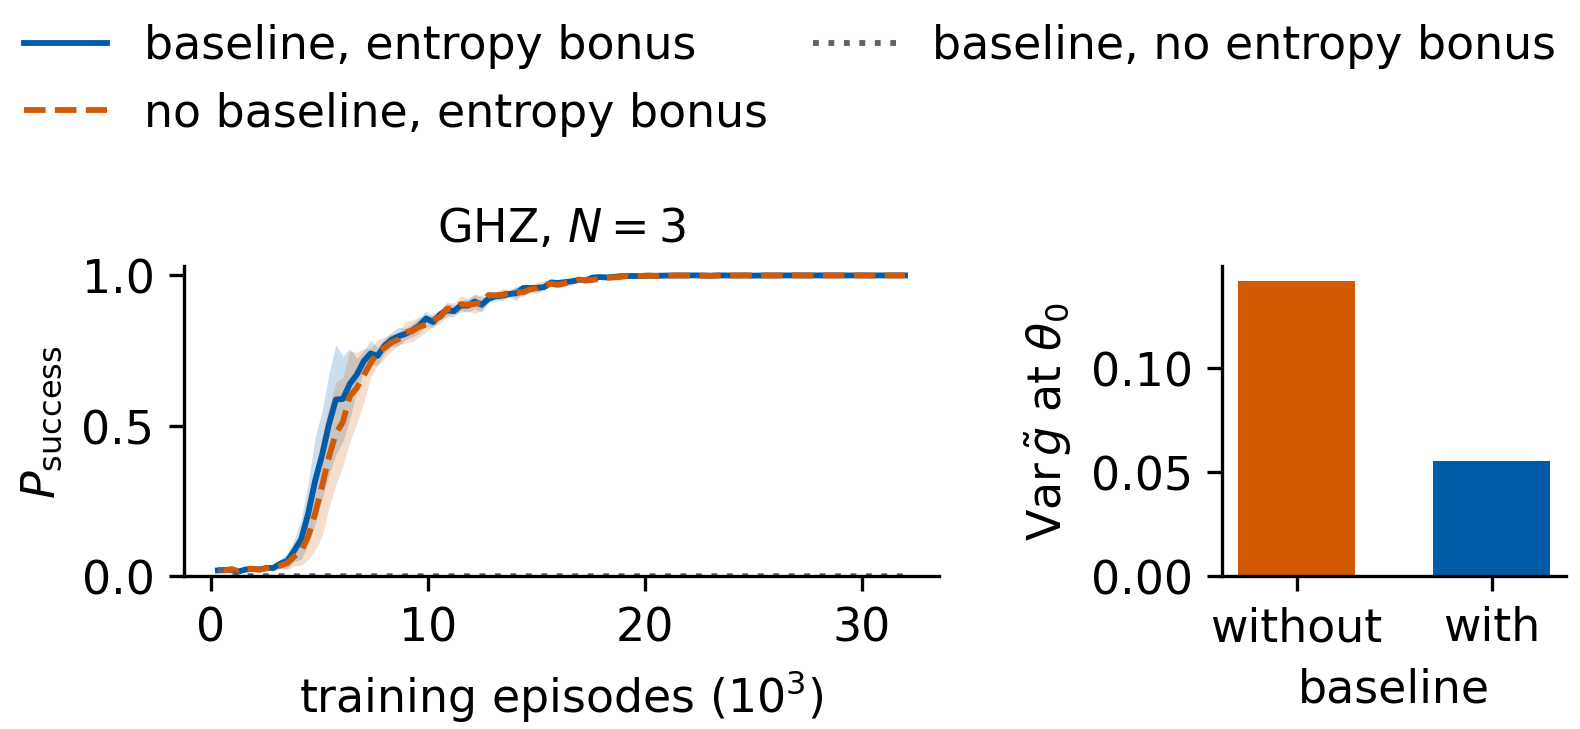

In [35]:
BL_STYLE = {"baseline, entropy bonus": dict(color=UJBlue, ls="-"), "no baseline, entropy bonus": dict(color=DSOrange, ls="--"),
            "baseline, no entropy bonus": dict(color=UJGray, ls=":")}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
    ax = axs[0]
    for label, d in BL.items():
        p = d["p"].reshape(d["p"].shape[0], -1, 10).mean(-1)      # mean over 10 consecutive updates
        ep = (np.arange(p.shape[1]) + 1) * 10 * PG_CFG["batch"] / 1e3
        m, sd = p.mean(0), p.std(0)
        ax.fill_between(ep, np.clip(m - sd, 0, 1), np.clip(m + sd, 0, 1), color=BL_STYLE[label]["color"], alpha=0.2, lw=0)
        ax.plot(ep, m, label=label, **BL_STYLE[label])
    ax.set_xlabel(r"training episodes ($10^3$)"); ax.set_ylabel(r"$P_{\rm success}$")
    ax.set_ylim(0, 1.03); ax.set_title(rf"GHZ, $N={N_BL}$")
    ax = axs[1]
    ax.bar([0, 1], [GVAR["without baseline"], GVAR["with baseline"]], color=[DSOrange, UJBlue], width=0.6)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["without", "with"]); ax.set_xlabel("baseline")
    ax.set_ylabel(r"$\mathrm{Var}\,\tilde g$ at $\theta_0$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02),
               handlelength=1.8, columnspacing=1.0)
    fig.tight_layout(rect=(0, 0, 1, 0.8)); save(fig, "fig_lab052_pg_baseline"); plt.show()

With the entropy bonus all eight agents learn the GHZ circuit, with and without the baseline. Without the bonus no agent reaches the target, and $P_{\rm success}$ stays at zero, since the policy concentrates on phase gates that leave $|000\rangle$ unchanged. This is the collapse described above, and it is the reason for the bonus.

The baseline lowers the variance of the gradient estimate at the initial policy by the printed factor of 2.6. In the learning curves its effect is small. The agents with the baseline reach $P_{\rm success}=0.5$ after a median of 4\,784 episodes and those without it after 5\,168, and the bands of the two variants overlap. A possible reason, which we have not tested, is that early in training the entropy term dominates the gradient and keeps the policy close to uniform in both variants.

<hr/>
## 11. Deep Q-learning against policy gradient

We now train DQN, DDQN and REINFORCE agents on the GHZ and W states for every chain length of the notebook, $N=2$, $3$, $4$ and $6$, with five seeds per method. All three use the reward with the CNOT cost, the same gate set and input, the same episodes and the same number of gate applications per agent. A seed fixes the initial network, and the three agents of one seed share the hidden layers of their initial network. The policy network differs only by its zero output layer. The DQN and DDQN agents run with their trainer and settings from the training section, the REINFORCE agents with the baseline and the entropy schedule introduced above.

In [36]:
H2H_TARGETS, H2H_SEEDS, METHODS = ["GHZ", "W"], [0, 1, 2, 3, 4], ["DQN", "DDQN", "PG"]
H2H_LOGS, PG_PARAMS = {}, {}
for N in N_LIST:
    env = make_env(N); cost = cost_vector(env)
    t0 = time.time()
    # DQN and DDQN: the trainer of the earlier sections with the per-gate cost
    runs_q = [(t, algo, s) for t in H2H_TARGETS for algo in ALGOS for s in H2H_SEEDS]
    nd = max(d for d in range(1, len(jax.devices()) + 1) if len(runs_q) % d == 0)
    sh = lambda x: x.reshape((nd, -1) + x.shape[1:])
    logs = jax.block_until_ready(jax.pmap(jax.vmap(make_trainer(env, CFG)))(
        sh(jnp.stack([jax.random.PRNGKey(3000 + 100 * N + 10 * H2H_TARGETS.index(t) + s) for t, _, s in runs_q])),
        sh(jnp.stack([TARGETS[N][t] for t, _, _ in runs_q])), sh(jnp.array([a == "DDQN" for _, a, _ in runs_q])),
        sh(jnp.stack([cost] * len(runs_q))), sh(jnp.zeros(len(runs_q), bool)), sh(jnp.zeros(len(runs_q), jnp.int32))))
    fids, acts, _, n_ep = (np.asarray(x).reshape((len(runs_q),) + x.shape[2:]) for x in logs)
    steps = (np.arange(fids.shape[1]) + 1) * CFG["eval_every"] * CFG["n_env"]      # n_env gates per update
    for i, (t, algo, s) in enumerate(runs_q):
        H2H_LOGS[(N, t, algo, s)] = dict(fids=fids[i], acts=acts[i], episodes=n_ep[i], steps=steps)
    # policy gradient: the same keys, so the hidden layers start as those of the Q-networks
    runs_p = [(t, s) for t in H2H_TARGETS for s in H2H_SEEDS]
    nd = max(d for d in range(1, len(jax.devices()) + 1) if len(runs_p) % d == 0)
    sh = lambda x: x.reshape((nd, -1) + x.shape[1:])
    logs, params = jax.block_until_ready(jax.pmap(jax.vmap(make_pg_agent(env)["train"]))(
        sh(jnp.stack([jax.random.PRNGKey(3000 + 100 * N + 10 * H2H_TARGETS.index(t) + s) for t, s in runs_p])),
        sh(jnp.stack([TARGETS[N][t] for t, _ in runs_p])), sh(jnp.stack([cost] * len(runs_p))),
        sh(jnp.ones(len(runs_p))), sh(jnp.full(len(runs_p), PG_CFG["beta0"]))))
    fids, acts, _, n_ep, n_st = (np.asarray(x).reshape((len(runs_p),) + x.shape[2:]) for x in logs)
    for i, (t, s) in enumerate(runs_p):
        H2H_LOGS[(N, t, "PG", s)] = dict(fids=fids[i], acts=acts[i], episodes=n_ep[i], steps=n_st[i])
        PG_PARAMS[(N, t, s)] = jax.tree.map(lambda x: x.reshape((len(runs_p),) + x.shape[2:])[i], params)
    T_TRAIN[f"h2h {N}"] = time.time() - t0
    print(f"N = {N}: {len(runs_q)} Q-learning and {len(runs_p)} policy-gradient trainings in {T_TRAIN[f'h2h {N}']:.0f} s")

N = 2: 20 Q-learning and 10 policy-gradient trainings in 57 s


N = 3: 20 Q-learning and 10 policy-gradient trainings in 63 s


N = 4: 20 Q-learning and 10 policy-gradient trainings in 73 s


N = 6: 20 Q-learning and 10 policy-gradient trainings in 116 s


For every agent we take the greedy circuit after the last update, in which each gate is the one with the largest $Q_\theta$ or the largest probability. A run is a success when this circuit reaches $F>0.99$, and we cut it at the first such gate. An unsuccessful circuit is cut at its best fidelity, as for the trained agents earlier. The table lists for every target and method the number of successful seeds, the final fidelity $F_{\rm agent}$, the number of training episodes and of gate applications until the greedy circuit first reached $F>0.99$, and the gate count $n$ and CNOT count of every successful circuit, with the reference circuit of the exact search below each target.

In [37]:
def reference(N, t):
    # fidelity, gate count and CNOT count of the reference circuit, or None where no exact reference exists
    if t == "GHZ":
        return dict(F=1.0, n=N, n_cx=N - 1)
    if N in (2, 3):
        o = OPT[(N, t, "CNOT")]
        return dict(F=o["F"], n=o["n"], n_cx=o["n_cx"])
    return None

H2H = {}
for N in N_LIST:
    names = make_env(N)["gate_names"]
    for t in H2H_TARGETS:
        for m in METHODS:
            rows = []
            for s in H2H_SEEDS:
                L = H2H_LOGS[(N, t, m, s)]
                F_end, n_end = episode_end(L["fids"][-1])          # final greedy circuit, cut at its first F > 0.99
                F_best, n_best = circuit_summary(L["fids"][-1])     # or at its best fidelity
                ok = F_end > F_SUCCESS
                n = n_end if ok else n_best
                gates = [names[a] for a in L["acts"][-1][:n]]
                hit = np.nonzero(L["fids"].max(1) > F_SUCCESS)[0]
                rows.append(dict(F=F_end if ok else F_best, success=ok, n=n, n_cx=n_cnot(gates), gates=gates,
                                 episodes=int(L["episodes"][hit[0]]) if len(hit) else None,
                                 steps=int(L["steps"][hit[0]]) if len(hit) else None))
            H2H[(N, t, m)] = rows

def fmt_range(x):
    x = [v for v in x if v is not None]
    return "-" if not x else (f"{np.median(x):,.0f} [{min(x):,}-{max(x):,}]")

print("success: seeds with F > 0.99;  F_agent: mean [min-max];  episodes and gate applications to the first success:"
      " median [min-max];\n(n, CNOTs) of the successful circuits;  reference (n, CNOTs) and its fidelity")
for t in H2H_TARGETS:
    for N in N_LIST:
        ref = reference(N, t)
        ref_s = f"{ref['n']}, {ref['n_cx']} (F = {ref['F']:.3f})" if ref else (f"F*(9) = {W4_LOWER:.3f}" if N == 4 else "none")
        if (N, t) == (2, "W"):
            ref_s += f", shortest {OPT[(2, 'W', 'uniform')]['n']}, {OPT[(2, 'W', 'uniform')]['n_cx']}"
        for m in METHODS:
            rows = H2H[(N, t, m)]
            F = np.array([r["F"] for r in rows])
            succ = [(r["n"], r["n_cx"]) for r in rows if r["success"]]
            print(f"{t + '_' + str(N):5s} {m:4s} {sum(r['success'] for r in rows)}/{len(rows)}  "
                  f"F {F.mean():.3f} [{F.min():.3f}-{F.max():.3f}]  ep {fmt_range([r['episodes'] for r in rows]):20s}"
                  f" steps {fmt_range([r['steps'] for r in rows]):24s} {succ}")
        print(f"{'':10s} reference: {ref_s}")

success: seeds with F > 0.99;  F_agent: mean [min-max];  episodes and gate applications to the first success: median [min-max];
(n, CNOTs) of the successful circuits;  reference (n, CNOTs) and its fidelity
GHZ_2 DQN  0/5  F 0.500 [0.500-0.500]  ep -                    steps -                        []
GHZ_2 DDQN 5/5  F 1.000 [1.000-1.000]  ep 2,224 [2,212-4,525]  steps 16,000 [16,000-32,000]   [(2, 1), (2, 1), (2, 1), (2, 1), (2, 1)]
GHZ_2 PG   5/5  F 1.000 [1.000-1.000]  ep 1,984 [1,984-1,984]  steps 12,328 [12,198-12,731]   [(2, 1), (2, 1), (2, 1), (2, 1), (2, 1)]
           reference: 2, 1 (F = 1.000)
GHZ_3 DQN  1/5  F 0.550 [0.250-1.000]  ep 17,822 [1,613-34,031] steps 168,000 [16,000-320,000] [(3, 2)]
GHZ_3 DDQN 5/5  F 1.000 [1.000-1.000]  ep 1,615 [1,605-3,269]  steps 16,000 [16,000-32,000]   [(3, 2), (3, 2), (3, 2), (3, 2), (3, 2)]
GHZ_3 PG   5/5  F 1.000 [1.000-1.000]  ep 6,400 [4,800-6,400]  steps 59,340 [46,429-61,008]   [(3, 2), (3, 2), (3, 2), (3, 2), (3, 2)]
           ref

The three methods agree on the shortest GHZ circuits wherever they reach them. Every successful GHZ circuit has $N$ gates and $N-1$ CNOTs, the optimum. They differ in how often they reach it. DDQN learns the GHZ state in all five seeds for $N=2$, $3$ and $4$, plain DQN in none, one and three seeds, and REINFORCE in all seeds for $N=2$ and $3$ and in none for $N=4$. For $N=6$ no agent of any method reaches the GHZ state within the training budget, and all of them stay at $F=0.5$, the fidelity of $|0\dots0\rangle$.

For the two-qubit W state REINFORCE succeeds in all five seeds and DDQN in three, and plain DQN in none. The two methods find different circuits. All REINFORCE circuits are shortest circuits, five gates with two CNOTs, and under the CNOT cost their discounted return is $0.768$. The successful DDQN circuits use a single CNOT, two of them with six gates, the circuit with the best return $G_*=0.773$ under the CNOT cost, and one with seven gates. For three, four and six qubits no method reaches $F>0.99$, as the exact search predicts for $N=3$, and the mean fidelities stay well below the exact optimum $0.829$ for $N=3$ and the lower bound $0.562$ for $N=4$.

The numbers of episodes until the first success are known only to the resolution of the records, every $16\,000$ gate applications, and they compare the speed of the methods on the targets that both learn. For the two-qubit GHZ state DDQN and REINFORCE need about two thousand episodes. For three qubits DDQN reaches the target at the first record, after $16\,000$ gate applications, and REINFORCE after about $60\,000$ gate applications.

The figure collects the comparison. The upper panels show the final fidelity $F_{\rm agent}$ for the GHZ and the W state, the mean over five seeds with the range as error bar, and the dotted lines mark the exact best fidelity where it is known. The lower left panel counts the seeds whose greedy circuit reaches $F>0.99$, with filled bars for the GHZ state and open bars for the W state, and the lower right panel shows the number of training episodes until the first success of every successful seed, with filled markers for the GHZ state and open markers for the W state.

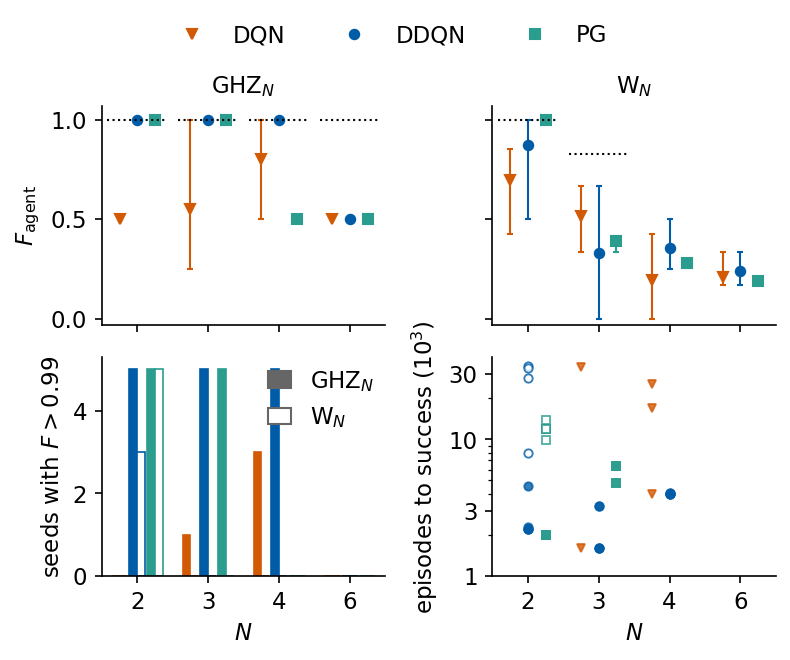

In [38]:
M_STYLE = {"DQN": dict(color=DSOrange, marker="v"), "DDQN": dict(color=UJBlue, marker="o"), "PG": dict(color="#2A9D8F", marker="s")}
x_of = lambda j, k: j + (k - 1) * 0.25                          # position of method k at the j-th chain length
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 4.4), sharex=True)
    for ax, t in zip(axs[0], H2H_TARGETS):                      # final fidelity, mean over seeds and range
        for k, m in enumerate(METHODS):
            F = np.array([[r["F"] for r in H2H[(N, t, m)]] for N in N_LIST])
            x = [x_of(j, k) for j in range(len(N_LIST))]
            ax.errorbar(x, F.mean(1), yerr=[F.mean(1) - F.min(1), F.max(1) - F.mean(1)], fmt="none", ecolor=M_STYLE[m]["color"],
                        elinewidth=1.0, capsize=1.5)
            ax.plot(x, F.mean(1), ls="none", ms=4.5, label=m, **M_STYLE[m])
        for j, N in enumerate(N_LIST):                          # exact best fidelity where it is known
            ref = reference(N, t)
            if ref:
                ax.plot([j - 0.42, j + 0.42], [ref["F"]] * 2, color="k", lw=1.0, ls=":")
        ax.set_ylim(-0.03, 1.07); ax.set_title(f"{t}$_N$")
    axs[0, 0].set_ylabel(r"$F_{\rm agent}$")
    axs[0, 1].set_yticklabels([])
    ax = axs[1, 0]                                              # number of successful seeds, GHZ and W
    for k, m in enumerate(METHODS):
        for t, fill in (("GHZ", True), ("W", False)):
            n_ok = [sum(r["success"] for r in H2H[(N, t, m)]) for N in N_LIST]
            dx = -0.055 if t == "GHZ" else 0.055
            ax.bar([x_of(j, k) + dx for j in range(len(N_LIST))], n_ok, width=0.11, color=M_STYLE[m]["color"] if fill else "white",
                   edgecolor=M_STYLE[m]["color"], lw=0.8)
    ax.set_ylabel("seeds with $F>0.99$"); ax.set_ylim(0, len(H2H_SEEDS) + 0.3)
    ax.legend(handles=[mpl.patches.Patch(color="0.4", label=r"GHZ$_N$"), mpl.patches.Patch(fc="white", ec="0.4", label=r"W$_N$")],
              loc="upper right", handlelength=1.0, borderaxespad=0.1)
    ax = axs[1, 1]                                              # episodes until the first successful greedy circuit
    for k, m in enumerate(METHODS):
        for t, fill in (("GHZ", True), ("W", False)):
            for j, N in enumerate(N_LIST):
                e = [r["episodes"] for r in H2H[(N, t, m)] if r["episodes"] is not None]
                ax.plot([x_of(j, k)] * len(e), np.array(e) / 1e3, ls="none", ms=4, alpha=0.8,
                        mfc=M_STYLE[m]["color"] if fill else "white", mec=M_STYLE[m]["color"], mew=0.9, marker=M_STYLE[m]["marker"])
    ax.set_yscale("log"); ax.set_yticks([1, 3, 10, 30]); ax.set_yticklabels(["1", "3", "10", "30"])
    ax.set_ylabel(r"episodes to success ($10^3$)")
    for ax in axs[1]:
        ax.set_xticks(range(len(N_LIST))); ax.set_xticklabels(N_LIST); ax.set_xlabel("$N$"); ax.set_xlim(-0.5, len(N_LIST) - 0.5)
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.01))
    fig.tight_layout(rect=(0, 0, 1, 0.94)); save(fig, "fig_lab052_dqn_pg"); plt.show()

The fidelity panels show the same pattern for all three methods. Above $N=4$ for the GHZ state and above $N=2$ for the W state no method reaches the target, and their final fidelities lie close to each other. The differences between the methods appear at the transition, in the GHZ state of three and four qubits and in the two-qubit W state, where the number of successful seeds differs most.

### Sampled circuits

A trained DQN agent prepares one circuit, the greedy one. The REINFORCE policy assigns a probability to every circuit, and sampling it shows which circuits it has learned. For every successful REINFORCE seed we sample $1000$ episodes from the final policy and count the distinct circuits that reach $F>0.99$. We compare them with the shortest sequences counted by the exact search and with the distinct greedy circuits of the successful DQN and DDQN agents.

In [39]:
N_SAMPLE = 1000
DIST, SAMPLERS = {}, {}
for (N, t, s), params in PG_PARAMS.items():
    if not H2H[(N, t, "PG")][s]["success"]:
        continue
    env = make_env(N)
    if N not in SAMPLERS:
        SAMPLERS[N] = jax.jit(make_pg_agent(env)["rollout"], static_argnums=4)
    _, a, _, running, success = SAMPLERS[N](params, TARGETS[N][t], cost_vector(env), jax.random.PRNGKey(6000 + s), N_SAMPLE)
    a, running, success = np.asarray(a).T, np.asarray(running).T, np.asarray(success).T
    circuits = {}
    for i in np.nonzero(success.any(1))[0]:
        c = tuple(env["gate_names"][g] for g in a[i][running[i]])
        circuits[c] = circuits.get(c, 0) + 1
    DIST[(N, t, s)] = dict(p_success=success.any(1).mean(), circuits=circuits)

L_SHORT = {(N, "GHZ"): N for N in N_LIST} | {(2, "W"): 5}                # shortest successful length from the exact search
for N, t in sorted({(k[0], k[1]) for k in DIST}, key=lambda x: (x[1], x[0])):
    L, n_ref = L_SHORT[(N, t)], sum(SHORTEST_COUNT[(N, t, L_SHORT[(N, t)])].values())
    print(f"{t}_{N}: {N_SAMPLE} episodes from the final policy of each successful seed; {n_ref} shortest sequences of {L} gates exist")
    union = set()
    for s in H2H_SEEDS:
        if (N, t, s) not in DIST:
            continue
        d = DIST[(N, t, s)]
        short = {c: m for c, m in d["circuits"].items() if len(c) == L}
        union |= set(short)
        top = sorted(d["circuits"].items(), key=lambda x: -x[1])[:2]
        print(f"   seed {s}: success {d['p_success']:.3f}, shortest circuits {sum(short.values()) / N_SAMPLE:.3f} of the samples,"
              f" {len(short)} distinct shortest;  most frequent " + ",  ".join(f"{' '.join(c)} ({m})" for c, m in top))
    greedy_q = {tuple(r["gates"]) for m in ("DQN", "DDQN") for r in H2H[(N, t, m)] if r["success"]}
    print(f"   all seeds: {len(union)} of the {n_ref} shortest sequences sampled;"
          f"  distinct successful greedy circuits of DQN and DDQN: {len(greedy_q)} {sorted(greedy_q)}")

GHZ_2: 1000 episodes from the final policy of each successful seed; 2 shortest sequences of 2 gates exist
   seed 0: success 1.000, shortest circuits 0.995 of the samples, 2 distinct shortest;  most frequent H1 CX10 (824),  H0 CX01 (171)
   seed 1: success 1.000, shortest circuits 0.993 of the samples, 2 distinct shortest;  most frequent H1 CX10 (961),  H0 CX01 (32)
   seed 2: success 1.000, shortest circuits 0.993 of the samples, 2 distinct shortest;  most frequent H0 CX01 (961),  H1 CX10 (32)
   seed 3: success 1.000, shortest circuits 0.991 of the samples, 2 distinct shortest;  most frequent H1 CX10 (874),  H0 CX01 (117)
   seed 4: success 1.000, shortest circuits 0.994 of the samples, 2 distinct shortest;  most frequent H0 CX01 (899),  H1 CX10 (95)
   all seeds: 2 of the 2 shortest sequences sampled;  distinct successful greedy circuits of DQN and DDQN: 1 [('H0', 'CX01')]
GHZ_3: 1000 episodes from the final policy of each successful seed; 4 shortest sequences of 3 gates exist
   se

A single REINFORCE policy concentrates most of its weight on one shortest circuit and keeps a small weight on other circuits, among them other shortest circuits and a few longer ones. One three-qubit seed splits its weight almost equally between two shortest circuits that differ only in the order of the two CNOTs. Taken over the five seeds, the policies sample all shortest GHZ circuits for $N=2$ and $3$ and all eight shortest circuits of the two-qubit W state. The DQN and DDQN agents settle on one deterministic circuit per seed. Their six successful agents for the three-qubit GHZ state produce three distinct circuits together, and for the two-qubit GHZ state all of them produce the same circuit.

The final policies are still slightly random because the entropy bonus is switched off only after 60% of the training and the remaining updates sharpen the policy without making it deterministic. Every successful seed nevertheless samples a successful circuit in at least 997 of 1000 episodes, and a shortest one in at least 984.

### Value-based and policy-based learning

The two families learn different objects. DQN and DDQN learn the action values $Q_\theta(s,a)$, the expected return of every gate in every state, and act by choosing the largest one. REINFORCE learns the probabilities $\pi_\theta(a|s)$ directly and never estimates a value. For targets that end at success, such as GHZ, both maximise the same discounted return, and where they succeed they find circuits of the same length. For unreachable targets their continuation conventions at the time limit differ.

They explore differently. The DQN agents apply a random gate with probability $\epsilon$, which falls from 1 to $0.05$ over 60% of the training independently of what the agent has learned. Every transition enters the replay memory and is reused in many updates, and the Bellman target passes the large reward of the last CNOT of the GHZ circuit back to the earlier gates. The REINFORCE agents explore only through the randomness of their own policy and use each episode once. Without the entropy bonus they settle on the idle phase gates of $|0\dots0\rangle$ and never meet the target. With the bonus they learn the GHZ state up to three qubits and miss it for four qubits. One possible reason, untested here, is that random circuits reach the four-qubit GHZ state far more rarely than the three-qubit one, so the early batches contain too few successful episodes to steer the policy. The random policy of the early phase is the same as the $\epsilon=1$ phase of DQN, and the difference lies in what the two methods do with these episodes.

Stability depends on the method and the target. Plain DQN fails on several targets that DDQN learns in all seeds, the same ordering as in the earlier runs with the uniform gate cost. REINFORCE behaves alike in all five seeds of a target, successful in every seed for the two- and three-qubit GHZ states and the two-qubit W state and unsuccessful in every seed for the other targets. A trained policy also carries more than one answer, as the sampled circuits show.

The policy-gradient estimate needs only the probability $\pi_\theta(a|s)$ of the chosen action and its gradient. It never takes a maximum over the actions. This is what extends it to gates with continuous parameters, for example a rotation $\hat R_x(\varphi)=e^{-i\varphi \hat X/2}$ with any angle $\varphi$. The policy then becomes a probability density over the angle, such as a Gaussian whose mean and width are network outputs, and the same estimator applies with $\ln\pi_\theta$ of that density. Q-learning would need the maximum of $Q_\theta(s,a)$ over a continuum of actions in every target, which is itself an optimisation problem. A continuous gate set contains the angles that the W state needs, such as $\arccos(1/\sqrt3)$ for three qubits, which the discrete gate set reaches only approximately.

The scope of this comparison is set by the runs above. Two target families, chain lengths up to six qubits, five seeds per method, about $3.2\times10^5$ gate applications per agent, and a tuning budget that differs between the methods, nine trial settings for REINFORCE and none beyond the earlier sections for DQN and DDQN. Other learning rates, longer training or a learned baseline could change the success rates, in particular for the four-qubit GHZ state.

<hr/>
## 12. Target difficulty, overestimation and policy gradient

Small targets that need few gates and whose fidelity rises along the circuit are learned by both algorithms. The GHZ state becomes hard as $N$ grows although its shortest circuit is known and has only $N$ gates. Its fidelity drops to $1/4$ after the first gate and stays there until the last CNOT, and an exploring agent with $5N-2$ gates finds this sequence by chance only rarely. The transverse-field ground state at $h=2$ is close to $|+\dots+\rangle$, and the fidelity rises with every Hadamard gate, so most agents find the Hadamard circuit at every $N$. The W state and the non-integrable ground state need rotation angles that the discrete gate set reaches only through long circuits, and their best fidelity is clearly below 1 already in the exhaustive search for three qubits. For the non-integrable ground state the initial fidelity falls to almost zero as $N$ grows, and flipping a spin with our gates takes at least four of them, for example $\hat X=\hat H\hat S\hat S\hat H$, during which the reward stays near zero.

In these runs the agent succeeds where the reward guides it along the circuit, and it falls short of the optimum where the reward offers a long plateau, a fidelity near zero, or a target that the gate set reaches only with long circuits. Entanglement is only one ingredient of this difficulty, and its correlation with the reached fidelity is weak. A gate set with continuous rotation angles would remove the need for long approximating circuits, and the task becomes a continuous control problem.

With the exact reward DDQN reaches the target more often than DQN, by a margin that three seeds per target determine only roughly. With a fidelity estimated from ten measurement shots the difference is large and has a clear mechanism. DQN overestimates the value of the initial state by more than a factor of two and none of its agents learns the GHZ circuit, while DDQN keeps the value at the exact optimum and learns the circuit in three of five seeds. In this study, on the three-qubit GHZ target with exact-state input and success judged by the exact fidelity, separating the choice of the next action from its evaluation allows deep Q-learning to learn the circuit from rewards measured with ten shots in three of five seeds.

The policy-gradient agent learns the shortest GHZ circuits for two and three qubits and a shortest two-qubit W circuit in every seed, and its trained policies spread their weight over several equivalent shortest circuits. It needs an entropy bonus to explore, it fails on the four-qubit GHZ state, which DDQN learns in every seed, and in this five-seed comparison no method reaches the six-qubit GHZ state or the W state beyond two qubits within the training budget. The earlier uniform-cost survey reached the six-qubit GHZ state in one of three DQN seeds and one of three DDQN seeds.

The scope of these statements is set by the runs of this notebook, six targets on chains of two to six qubits with three seeds each, one shot-noise study on the three-qubit GHZ state with five seeds, a comparison of DQN, DDQN and REINFORCE on the GHZ and W states with five seeds each, and $10^4$ DQN updates or the same number of gate applications per agent. Eight-qubit chains, longer training or other rewards could change the success rates.